
# 4. VERİ TEMİZLEME (DATA CLEANING)

### 4.1. Eksik Değerlerin İncelenmesi

**Amaç:**

400.000 kayıtlık Edge-IIoTset çalışma veri setindeki eksik, boş ve şüpheli değerleri tespit ederek veri kalitesini değerlendirmek.

**Yöntem:**

Pandas kütüphanesi kullanılarak veri seti parçalar halinde okunacaktır.

Aşağıdaki kontroller gerçekleştirilecektir:

1. Boş veya yalnızca boşluk içeren hücrelerin tespiti.
2. NaN, NULL, None, N/A, NA ve ? gibi eksik değer göstergelerinin incelenmesi.
3. Eksik değerlerin sütun bazında sayılması.
4. Şüpheli değer içeren sütunların belirlenmesi.

**Önemli Not:**

Sıfır (0) değerleri otomatik olarak eksik kabul edilmeyecektir. Ağ protokollerine ait bazı alanlarda sıfır değerleri farklı anlamlar taşıyabilir.

Bu aşamada herhangi bir kayıt silinmeyecek veya değiştirilmeyecektir.


**Çalıştırma uyarısı:** Bu notebook, veri temizlemenin farklı aşamalarında yeni CSV dosyaları oluşturur. Özellikle 4.6 ve 4.8 gibi adımlarda önceden üretilmiş dosyaların üzerine yazılması güvenlik amacıyla engellenir. **Kaydedilmiş sonuçları görüntülemek için kodları yeniden çalıştırmanız gerekmez.**


In [5]:

import pandas as pd
from pathlib import Path

# Çalışma veri setinin dosya yolu
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_400000_korumali.csv"
)

# Dosyanın mevcut olduğunu kontrol etme
if not dosya_yolu.is_file():
    raise FileNotFoundError(
        f"Dosya bulunamadı: {dosya_yolu}"
    )

# Sütun isimlerini belirleme
sutunlar = pd.read_csv(
    dosya_yolu, nrows=0
).columns.tolist()

# Eksik değer sayaçları
bos_sayilari = pd.Series(
    0, index=sutunlar, dtype="int64"
)

ozel_sayilari = pd.Series(
    0, index=sutunlar, dtype="int64"
)

# Özel eksik değer göstergeleri
ozel_isaretler = {
    "nan", "null", "none", "n/a", "na", "?"
}

toplam_kayit = 0

# Dosyayı parçalar halinde okuma
for parca in pd.read_csv(
    dosya_yolu,
    chunksize=10000,
    dtype=str,
    keep_default_na=False,
    na_filter=False
):

    toplam_kayit += len(parca)

    for sutun in sutunlar:

        degerler = parca[sutun].str.strip()

        # Boş değerlerin sayılması
        bos_sayilari[sutun] += int(
            degerler.eq("").sum()
        )

        # Özel eksik değerlerin sayılması
        ozel_sayilari[sutun] += int(
            degerler.str.lower().isin(
                ozel_isaretler
            ).sum()
        )

# Sonuç tablosu
eksik_deger_tablosu = pd.DataFrame({
    "Sütun Adı": sutunlar,
    "Boş Hücre": bos_sayilari.values,
    "Özel Eksik İşareti": ozel_sayilari.values
})

eksik_deger_tablosu["Toplam Şüpheli"] = (
    eksik_deger_tablosu["Boş Hücre"]
    + eksik_deger_tablosu["Özel Eksik İşareti"]
)

supheli_sutunlar = eksik_deger_tablosu[
    eksik_deger_tablosu["Toplam Şüpheli"] > 0
].sort_values(
    "Toplam Şüpheli", ascending=False
)

print("İncelenen kayıt:", toplam_kayit)
print("İncelenen sütun:", len(sutunlar))
print("Toplam boş hücre:", int(bos_sayilari.sum()))
print("Toplam özel eksik işareti:", int(ozel_sayilari.sum()))
print("Şüpheli değer içeren sütun sayısı:",
      len(supheli_sutunlar))

print("\nEksik Değer Analizi Sonuçları:")

if len(supheli_sutunlar) > 0:
    display(supheli_sutunlar)
else:
    print("Tanımlanan eksik değer bulunamadı.")


İncelenen kayıt: 400000
İncelenen sütun: 63
Toplam boş hücre: 0
Toplam özel eksik işareti: 0
Şüpheli değer içeren sütun sayısı: 0

Eksik Değer Analizi Sonuçları:
Tanımlanan eksik değer bulunamadı.



### 4.1. Eksik Değerlerin İncelenmesi — Sonuç ve Yorum

Edge-IIoTset veri setinden oluşturulan 400.000 kayıtlık çalışma veri setindeki eksik ve boş değerler analiz edilmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

- İncelenen toplam kayıt sayısı: 400.000
- İncelenen sütun sayısı: 63
- Boş hücre sayısı: 0
- Özel eksik değer işareti sayısı: 0
- Şüpheli değer içeren sütun sayısı: 0

#### Bulguların Değerlendirilmesi

Pandas kütüphanesi kullanılarak veri setindeki tüm sütunlar eksik değer göstergeleri açısından incelenmiştir.

Analiz sonucunda boş hücre veya tanımlanan özel eksik değer işaretlerinden herhangi biri tespit edilmemiştir.

Bu bulgu, veri setinde kontrol edilen eksik değer türleri açısından bir sorun gözlemlenmediğini göstermektedir.

Ancak sıfır (0) ve 0.0 gibi sayısal değerler eksik veri olarak değerlendirilmemiştir. Bu değerler ağ protokollerine ait özelliklerde geçerli, uygulanamayan veya özel anlam taşıyan alanları temsil edebilir.

Ayrıca mevcut analiz, hatalı veri biçimlerini, sonsuz sayısal değerleri ve yinelenen kayıtları kapsamamaktadır.

#### Sonuç

400.000 kayıtlık çalışma veri setinde kontrol edilen boş hücreler ve özel eksik değer göstergeleri bulunmamıştır.

Bu nedenle mevcut aşamada eksik değer doldurma (Imputation) veya eksik değer nedeniyle kayıt silme işlemi uygulanmamıştır.

Veri kalitesinin daha ayrıntılı değerlendirilmesi amacıyla sonraki aşamalarda yinelenen kayıtlar, veri tipi tutarlılığı ve aykırı değerler incelenecektir.



### 4.2. Yinelenen Kayıtların İncelenmesi (Duplicate Analysis)

**Amaç:**

400.000 kayıtlık Edge-IIoTset çalışma veri setinde yinelenen kayıtların bulunup bulunmadığını belirlemek.

**Yöntem:**

Veri seti parçalar halinde okunarak satırların tüm 63 sütundaki değerleri karşılaştırılacaktır.

Bellek kullanımını azaltmak için satırlara hash değerleri atanacak ve aynı hash değerine sahip kayıtlar olası tam satır tekrarları olarak sayılacaktır.

Bu yöntem hızlı bir ön kontrol sağlamaktadır. Hash çakışması olasılığı bulunduğundan sonuçlar gerektiğinde doğrudan satır karşılaştırmasıyla doğrulanacaktır.

**Beklenen Çıktılar:**

- Toplam kayıt sayısı
- Olası yinelenen kayıt sayısı
- Yinelenen kayıt oranı (%)

Bu aşamada herhangi bir kayıt silinmeyecek veya değiştirilmeyecektir.


In [6]:

import pandas as pd
from pathlib import Path

# Çalışma veri setinin dosya yolu
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_400000_korumali.csv"
)

# Daha önce görülen satır hash değerleri
gorulen_hashler = set()

# Analiz sayaçları
toplam_kayit = 0
tekrar_sayisi = 0

# Veri setini parçalar halinde okuma
for parca in pd.read_csv(
    dosya_yolu,
    chunksize=10000,
    dtype=str,
    keep_default_na=False,
    na_filter=False
):

    toplam_kayit += len(parca)

    # Her satırın tüm sütunlarını dikkate alarak hash oluşturma
    satir_hashleri = pd.util.hash_pandas_object(
        parca,
        index=False
    )

    # Önceden görülen satırları kontrol etme
    for hash_degeri in satir_hashleri:

        deger = int(hash_degeri)

        if deger in gorulen_hashler:
            tekrar_sayisi += 1
        else:
            gorulen_hashler.add(deger)

# Yinelenen kayıt oranını hesaplama
tekrar_orani = (
    tekrar_sayisi / toplam_kayit * 100
)

print("Toplam kayıt sayısı:", toplam_kayit)
print("Olası yinelenen kayıt sayısı:", tekrar_sayisi)

print(
    "Yinelenen kayıt oranı (%):",
    round(tekrar_orani, 4)
)

print(
    "Farklı satır hash sayısı:",
    len(gorulen_hashler)
)

print("\nDuplicate analizi tamamlandı.")


Toplam kayıt sayısı: 400000
Olası yinelenen kayıt sayısı: 198
Yinelenen kayıt oranı (%): 0.0495
Farklı satır hash sayısı: 399802

Duplicate analizi tamamlandı.



### 4.2. Yinelenen Kayıtların İncelenmesi — Sonuç ve Yorum

Edge-IIoTset veri setinden oluşturulan 400.000 kayıtlık çalışma veri setinde yinelenen kayıtların tespit edilmesi amacıyla hash tabanlı ön analiz gerçekleştirilmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

- Toplam kayıt sayısı: 400.000
- Olası yinelenen kayıt sayısı: 198
- Olası yinelenen kayıt oranı: %0,0495
- Farklı satır hash değeri sayısı: 399.802

#### Bulguların Değerlendirilmesi

Pandas kütüphanesinin `hash_pandas_object()` fonksiyonu kullanılarak her satırın 63 sütundaki değerleri üzerinden hash değeri hesaplanmıştır.

Analiz sonucunda toplam 198 adet tekrar eden hash değeri gözlemlenmiştir.

Bu oran, çalışma veri setinin yaklaşık %0,05'ine karşılık gelmektedir.

Ancak hash çakışması olasılığı nedeniyle tekrar eden hash değerlerinin tamamının kesin olarak aynı kayıtları temsil ettiği henüz doğrulanmamıştır.

Ayrıca ağ trafiğinde aynı özelliklere sahip kayıtların tekrarlanması her zaman veri hatası anlamına gelmemektedir.

#### Sonuç

Çalışma veri setinde 198 adet olası yinelenen kayıt tespit edilmiştir.

Bu kayıtların kesin olarak yinelenen satırlar olup olmadığı doğrudan veri karşılaştırmasıyla doğrulanacaktır.

Bu aşamada hiçbir kayıt silinmemiş veya değiştirilmemiştir.



### 4.3. Yinelenen Kayıtların Doğrulanması

**Amaç:**

Hash tabanlı analizde tespit edilen olası yinelenen kayıtların gerçekten aynı satır değerlerine sahip olup olmadığını belirlemek.

**Yöntem:**

Veri seti parçalar halinde okunarak birden fazla kez görülen hash değerleri belirlenecektir.

Aynı hash değerine sahip kayıtların 63 sütundaki gerçek değerleri karşılaştırılarak kesin yinelenen kayıt sayısı hesaplanacaktır.

**Beklenen Çıktılar:**

- Olası yinelenen kayıt sayısı
- Doğrulanmış yinelenen kayıt sayısı
- Hash çakışması nedeniyle oluşan farklılıkların belirlenmesi

Bu aşamada veri silme işlemi uygulanmayacaktır.


In [7]:

import pandas as pd
from collections import defaultdict

# Daha önce kullanılan çalışma veri seti
# dosya_yolu değişkeni mevcut olmalıdır.

# İlk geçiş: Tekrarlanan hash değerlerini bulma
gorulen = set()
aday_hashler = set()

for parca in pd.read_csv(
    dosya_yolu,
    chunksize=10000,
    dtype=str,
    keep_default_na=False,
    na_filter=False
):
    hashler = pd.util.hash_pandas_object(
        parca, index=False
    )

    for h in hashler:
        h = int(h)

        if h in gorulen:
            aday_hashler.add(h)
        else:
            gorulen.add(h)

print("Tekrarlanan hash grubu:", len(aday_hashler))

# İkinci geçiş: Yalnızca şüpheli satırları toplama
aday_satirlar = defaultdict(list)

for parca in pd.read_csv(
    dosya_yolu,
    chunksize=10000,
    dtype=str,
    keep_default_na=False,
    na_filter=False
):
    hashler = pd.util.hash_pandas_object(
        parca, index=False
    )

    # Tekrarlanan hash değerlerine sahip satırları seçme
    maske = hashler.isin(aday_hashler)

    for h, satir in zip(
        hashler[maske],
        parca.loc[maske].itertuples(
            index=False, name=None
        )
    ):
        aday_satirlar[int(h)].append(satir)

# Gerçek satır değerleriyle doğrulama
kesin_tekrar = 0

for satirlar in aday_satirlar.values():

    benzersiz_satirlar = set()

    for satir in satirlar:

        if satir in benzersiz_satirlar:
            kesin_tekrar += 1
        else:
            benzersiz_satirlar.add(satir)

print("\nDOĞRULAMA SONUÇLARI")
print("Kesin yinelenen kayıt:", kesin_tekrar)

print(
    "Kesin yinelenen kayıt oranı (%):",
    round(kesin_tekrar / 400000 * 100, 4)
)

print(
    "Benzersiz kayıt sayısı:",
    400000 - kesin_tekrar
)


Tekrarlanan hash grubu: 8

DOĞRULAMA SONUÇLARI
Kesin yinelenen kayıt: 198
Kesin yinelenen kayıt oranı (%): 0.0495
Benzersiz kayıt sayısı: 399802



### 4.3. Yinelenen Kayıtların Doğrulanması — Sonuç ve Yorum

400.000 kayıtlık Edge-IIoTset çalışma veri setinde, önceki aşamada hash yöntemiyle belirlenen olası yinelenen kayıtlar doğrudan satır karşılaştırmasıyla doğrulanmıştır.

#### Analiz Sonucunda Elde Edilen Bulgular

- Toplam kayıt sayısı: 400.000
- Tekrarlanan hash grubu sayısı: 8
- Doğrulanmış yinelenen kayıt sayısı: 198
- Yinelenen kayıt oranı: %0,0495
- Benzersiz tam satır sayısı: 399.802

#### Bulguların Değerlendirilmesi

İlk aşamada Pandas kütüphanesinin `hash_pandas_object()` fonksiyonu kullanılarak olası yinelenen kayıtlar tespit edilmiştir.

İkinci aşamada aynı hash değerine sahip satırların gerçek içerikleri karşılaştırılarak 198 adet yinelenen kayıt doğrulanmıştır.

Bu sonuç, çalışma veri setinde tüm 63 sütun bakımından tamamen aynı değerlere sahip kayıtların bulunduğunu göstermektedir.

Yinelenen kayıtların toplam veri setine oranı %0,0495 olup oldukça düşüktür.

Ancak ağ trafiğinde aynı özelliklere sahip kayıtların tekrar etmesi her zaman veri toplama hatası anlamına gelmemektedir. Bu nedenle tekrarların hangi trafik sınıflarında bulunduğunun ayrıca araştırılması gerekmektedir.

#### Makine Öğrenmesi Açısından Önemi

Aynı kayıtların hem eğitim hem de test veri kümelerinde bulunması veri sızıntısına (Data Leakage) neden olabilir.

Bu durum, sınıflandırma modellerinin performansının olduğundan yüksek görünmesine yol açabilir.

Bu nedenle eğitim-test ayrımı gerçekleştirilmeden önce yinelenen kayıtların uygun şekilde ele alınması gerekmektedir.

#### Sonuç

400.000 kayıtlık veri setinde 198 adet kesin yinelenen kayıt doğrulanmıştır.

Bu aşamada herhangi bir kayıt silinmemiştir.

Sonraki aşamada yinelenen kayıtların saldırı türlerine göre dağılımı incelenerek veri temizleme stratejisi belirlenecektir.



### 4.4. Yinelenen Kayıtların Sınıflara Göre Analizi

**Amaç:**

Doğrulanmış 198 yinelenen kaydın hangi normal trafik veya saldırı sınıflarında bulunduğunu belirlemek.

**Yöntem:**

Önceki analizde doğrulama amacıyla toplanan satırlar kullanılarak her saldırı türündeki yinelenen kayıt sayısı hesaplanacaktır.

**Beklenen Çıktılar:**

- Sınıflara göre yinelenen kayıt sayıları
- Yinelenen kayıtların hangi trafik türlerinde yoğunlaştığı
- Veri temizleme kararına yönelik bulgular

Bu aşamada kayıt silme işlemi gerçekleştirilmeyecektir.


In [8]:

import pandas as pd
from collections import Counter

# Sütun isimlerini belirleme
sutun_adlari = pd.read_csv(
    dosya_yolu,
    nrows=0
).columns.tolist()

# Saldırı türünün sütun konumu
tur_indeksi = sutun_adlari.index("Attack_type")

# Sınıflara göre yinelenen kayıtları sayma
sinif_tekrarlari = Counter()

# Önceki aşamada oluşturulan aday satırları inceleme
for satirlar in aday_satirlar.values():

    # Tamamen aynı satırların tekrar sayılarını bulma
    tekrarlar = Counter(satirlar)

    for satir, adet in tekrarlar.items():

        if adet > 1:
            saldiri_turu = satir[tur_indeksi]

            # İlk kayıt korunarak fazla nüshaları sayma
            sinif_tekrarlari[saldiri_turu] += adet - 1

# Sonuç tablosunu oluşturma
tekrar_sinif_tablosu = pd.DataFrame(
    sinif_tekrarlari.items(),
    columns=["Saldırı Türü", "Yinelenen Kayıt"]
)

tekrar_sinif_tablosu = tekrar_sinif_tablosu.sort_values(
    "Yinelenen Kayıt",
    ascending=False
).reset_index(drop=True)

print("Toplam doğrulanmış yinelenen kayıt:",
      sum(sinif_tekrarlari.values()))

print("\nSınıflara göre yinelenen kayıtlar:")
display(tekrar_sinif_tablosu)

# Önceki analiz sonucu ile tutarlılığı kontrol etme
assert sum(sinif_tekrarlari.values()) == 198

print("\nSınıf bazında analiz tamamlandı.")


Toplam doğrulanmış yinelenen kayıt: 198

Sınıflara göre yinelenen kayıtlar:


,Saldırı Türü,Yinelenen Kayıt
0,MITM,190
1,Normal,7
2,DDoS_UDP,1



Sınıf bazında analiz tamamlandı.



### 4.4. Yinelenen Kayıtların Sınıflara Göre Analizi — Sonuç ve Yorum

400.000 kayıtlık Edge-IIoTset çalışma veri setinde doğrulanan 198 yinelenen kaydın saldırı sınıflarına göre dağılımı analiz edilmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

| Sınıf | Toplam Kayıt | Yinelenen Kayıt | Tekrar Oranı (%) |
|---|---:|---:|---:|
| MITM | 300 | 190 | 63,3333 |
| Normal | 213.790 | 7 | 0,0033 |
| DDoS_UDP | 61.060 | 1 | 0,0016 |

Toplam 198 yinelenen kaydın 190 tanesinin MITM sınıfına ait olduğu belirlenmiştir.

#### Bulguların Değerlendirilmesi

Genel veri setindeki yinelenen kayıt oranı yalnızca %0,0495 olmasına rağmen, tekrarların sınıflar arasında eşit dağılmadığı görülmüştür.

Özellikle MITM sınıfında bulunan 300 kaydın 190 tanesi yinelenen ek kopyalardan oluşmaktadır.

Bu nedenle çalışma alt kümesindeki MITM kayıtlarının yalnızca 110 tanesi tüm sütunlar bakımından birbirinden farklıdır.

Bu durum, genel veri kalitesi göstergelerinin tek başına yeterli olmadığını ve sınıf bazında analiz yapılmasının önemini göstermektedir.

#### Makine Öğrenmesi Açısından Önemi

Yinelenen kayıtların eğitim ve test veri kümelerine birlikte dağılması, model performansının olduğundan yüksek değerlendirilmesine yol açabilir.

Özellikle azınlık sınıflarında bulunan yoğun tekrarlar, modelin farklı saldırı örüntülerini öğrenmesini sınırlandırabilir.

Bu nedenle eğitim-test ayrımından önce yinelenen kayıtların etkisinin değerlendirilmesi gerekmektedir.

#### Sonuç

Yinelenen kayıtların büyük bölümünün MITM saldırı sınıfında yoğunlaştığı tespit edilmiştir.

Mevcut aşamada herhangi bir kayıt silinmemiştir.

Bir sonraki aşamada orijinal MITM dosyasındaki benzersiz kayıt sayısı incelenerek örnekleme stratejisinin yeniden düzenlenmesine ihtiyaç olup olmadığı değerlendirilecektir.



### 4.5. Orijinal MITM Dosyasındaki Benzersiz Kayıtların İncelenmesi

**Amaç:**

Çalışma veri setinde yüksek tekrar oranına sahip olduğu belirlenen MITM sınıfının orijinal kaynak dosyasını incelemek.

**Yöntem:**

Orijinal MITM_attack.csv dosyasındaki tüm kayıtlar okunarak 63 sütunun tamamına göre yinelenen ve benzersiz satır sayıları hesaplanacaktır.

Bu analiz sonucunda azınlık sınıfı korumalı örnekleme stratejisinin yeniden düzenlenip düzenlenmeyeceği değerlendirilecektir.

Bu aşamada herhangi bir veri silinmeyecek veya değiştirilmeyecektir.


In [10]:

import pandas as pd
from pathlib import Path

# Orijinal Edge-IIoTset veri klasörünün yolu
veri_klasoru = Path(
    r"E:\Data mining\Network_Intrusion_Detection\archive\Edge-IIoTset dataset"
)

# MITM dosyasını klasör ve alt klasörlerde arama
bulunan_dosyalar = list(
    veri_klasoru.rglob("MITM_attack.csv")
)

# Dosyanın bulunduğunu doğrulama
if len(bulunan_dosyalar) != 1:
    raise FileNotFoundError(
        f"Beklenen tek MITM dosyası bulunamadı. "
        f"Bulunan dosya sayısı: {len(bulunan_dosyalar)}"
    )

mitm_dosyasi = bulunan_dosyalar[0]

print("İncelenen dosya:", mitm_dosyasi.name)

# Orijinal MITM kayıtlarını okuma
mitm_verileri = pd.read_csv(
    mitm_dosyasi,
    dtype=str,
    keep_default_na=False,
    na_filter=False
)

# Toplam kayıt sayısını hesaplama
toplam_mitm = len(mitm_verileri)

# Tüm 63 sütuna göre yinelenen kayıtları belirleme
tekrar_mitm = int(
    mitm_verileri.duplicated(
        keep="first"
    ).sum()
)

# Benzersiz kayıt sayısı
benzersiz_mitm = toplam_mitm - tekrar_mitm

# Yinelenen kayıt oranı
tekrar_orani = (
    tekrar_mitm / toplam_mitm * 100
)

print("\nORİJİNAL MITM DOSYASI ANALİZİ")
print("------------------------------")
print("Toplam kayıt:", toplam_mitm)
print("Yinelenen kayıt:", tekrar_mitm)
print("Benzersiz kayıt:", benzersiz_mitm)
print("Tekrar oranı (%):", round(tekrar_orani, 4))

print("\nÖRNEKLEME DEĞERLENDİRMESİ")

if benzersiz_mitm >= 300:
    print(
        "Orijinal MITM dosyasından "
        "300 benzersiz kayıt seçilebilir."
    )
else:
    print(
        "Orijinal MITM dosyasında "
        "300 benzersiz kayıt bulunmamaktadır."
    )


İncelenen dosya: MITM_attack.csv

ORİJİNAL MITM DOSYASI ANALİZİ
------------------------------
Toplam kayıt: 1229
Yinelenen kayıt: 819
Benzersiz kayıt: 410
Tekrar oranı (%): 66.6395

ÖRNEKLEME DEĞERLENDİRMESİ
Orijinal MITM dosyasından 300 benzersiz kayıt seçilebilir.



### 4.5. Orijinal MITM Dosyasındaki Benzersiz Kayıtların İncelenmesi — Sonuç ve Yorum

400.000 kayıtlık çalışma veri setinde MITM saldırı sınıfında yüksek oranda yinelenen kayıt bulunması üzerine orijinal `MITM_attack.csv` dosyası ayrıca incelenmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

- Orijinal MITM kayıt sayısı: 1.229
- Yinelenen ek kayıt sayısı: 819
- Benzersiz kayıt sayısı: 410
- Yinelenen kayıt oranı: %66,6395

#### Bulguların Değerlendirilmesi

Orijinal MITM dosyasındaki kayıtların yaklaşık %66,64'ünün tüm sütunlar bakımından yinelenen ek kopyalardan oluştuğu belirlenmiştir.

Önceki örnekleme sonucunda seçilen 300 MITM kaydının yalnızca 110 tanesinin benzersiz olduğu tespit edilmiştir.

Orijinal dosyada 410 benzersiz kayıt bulunduğundan, 300 farklı MITM kaydının tekrar seçimsiz olarak elde edilmesi mümkündür.

Bu durum, azınlık sınıflarının temsil gücünün yalnızca kayıt sayısıyla değil, kayıtların çeşitliliğiyle de değerlendirilmesi gerektiğini göstermektedir.

#### Makine Öğrenmesi Açısından Önemi

Yinelenen kayıtların eğitim ve test kümelerinde birlikte bulunması, model performansının olduğundan yüksek görünmesine neden olabilir.

MITM sınıfındaki farklı kayıtların sayısının artırılması, modelin daha çeşitli gözlemlerle eğitilmesine yardımcı olabilir.

Bununla birlikte benzersiz kayıtların eşit olasılıkla seçilmesi, orijinal trafik olaylarının tekrar sıklığını değiştirmektedir. Bu nedenle yeni örneklem orijinal MITM trafik dağılımının tam bir temsili değildir.

#### Sonuç

Orijinal MITM dosyasında 410 benzersiz kayıt bulunduğu doğrulanmıştır.

Çalışma veri setindeki MITM kayıtlarının 300 benzersiz örnekle yeniden oluşturulması uygun bir aday yaklaşım olarak belirlenmiştir.

Bu değişiklikte toplam örnek sayısının ve sınıf kotasının korunması, orijinal dosyaların değiştirilmemesi ve veri sızıntısının önlenmesi hedeflenmektedir.

Bu aşamada henüz herhangi bir kayıt değiştirilmemiştir.



### 4.6. MITM Örneklemesinin İyileştirilmesi

**Amaç:**

Çalışma veri setindeki MITM sınıfının benzersiz kayıt çeşitliliğini artırmak ve doğrulanmış tam satır tekrarlarının etkisini azaltmak.

**Yöntem:**

Orijinal MITM dosyasındaki 410 benzersiz kayıt arasından `random_state=42` kullanılarak tekrar seçimsiz 300 kayıt seçilecektir.

Mevcut çalışma veri setindeki 300 MITM kaydı bu örneklerle değiştirilecek, diğer sınıflara ait kayıtlar korunacaktır.

Orijinal çalışma veri setinin üzerine yazılmayacak, yeni bir CSV dosyası oluşturulacaktır.

**Beklenen Çıktı:**

- Toplam 400.000 kayıt
- MITM sınıfında 300 benzersiz kayıt
- Diğer sınıfların kayıt sayılarının korunması

**Sınırlılık:**

Bu işlem orijinal MITM sınıfındaki kayıt tekrar sıklıklarını değiştirecektir. Bu nedenle model değerlendirme aşamasında sınıf dağılımları ve veri sızıntısı riski ayrıca dikkate alınacaktır.


In [11]:

import pandas as pd
from pathlib import Path

# Proje ve veri yolları
proje_klasoru = Path(
    r"E:\Data mining\Network_Intrusion_Detection"
)

kaynak_klasoru = (
    proje_klasoru / "archive" / "Edge-IIoTset dataset"
)

calisma_klasoru = proje_klasoru / "Calisma_Verileri"

eski_dosya = (
    calisma_klasoru / "EdgeIIoT_400000_korumali.csv"
)

yeni_dosya = (
    calisma_klasoru / "EdgeIIoT_400000_MITM_benzersiz.csv"
)

gecici_dosya = (
    calisma_klasoru / "EdgeIIoT_400000_MITM_benzersiz.partial.csv"
)

# Var olan dosyaların üzerine yazılmasını önleme
if not eski_dosya.is_file():
    raise FileNotFoundError("400.000 kayıtlık kaynak dosya bulunamadı.")

if yeni_dosya.exists() or gecici_dosya.exists():
    raise FileExistsError(
        "Yeni veya geçici çıktı dosyası zaten mevcut."
    )

# Orijinal MITM dosyasını bulma
mitm_dosyalari = list(
    kaynak_klasoru.rglob("MITM_attack.csv")
)

if len(mitm_dosyalari) != 1:
    raise FileNotFoundError(
        "Orijinal MITM dosyası tekil olarak bulunamadı."
    )

# Orijinal MITM verilerini okuma
mitm = pd.read_csv(
    mitm_dosyalari[0],
    dtype=str,
    na_filter=False
)

# Benzersiz kayıtları belirleme
mitm_benzersiz = mitm.drop_duplicates()

assert len(mitm_benzersiz) == 410

# 300 farklı MITM kaydı seçme
yeni_mitm = mitm_benzersiz.sample(
    n=300,
    random_state=42,
    replace=False
)

# Sütun yapısını doğrulama
sutunlar = pd.read_csv(
    eski_dosya,
    nrows=0
).columns.tolist()

assert yeni_mitm.columns.tolist() == sutunlar
assert yeni_mitm["Attack_type"].str.strip().eq("MITM").all()
assert yeni_mitm["Attack_label"].str.strip().eq("1").all()

# Eski dosyadaki MITM kayıtlarını değiştirme
eski_mitm_sayisi = 0
diger_kayit_sayisi = 0
ilk_yazim = True

try:
    for parca in pd.read_csv(
        eski_dosya,
        chunksize=10000,
        dtype=str,
        na_filter=False
    ):

        mitm_maskesi = (
            parca["Attack_type"].str.strip().eq("MITM")
        )

        eski_mitm_sayisi += int(mitm_maskesi.sum())

        # MITM dışındaki bütün kayıtları koruma
        kalan_kayitlar = parca.loc[~mitm_maskesi]

        diger_kayit_sayisi += len(kalan_kayitlar)

        kalan_kayitlar.to_csv(
            gecici_dosya,
            mode="w" if ilk_yazim else "a",
            header=ilk_yazim,
            index=False,
            encoding="utf-8"
        )

        ilk_yazim = False

    # Önceki veri setiyle tutarlılık kontrolü
    assert eski_mitm_sayisi == 300
    assert diger_kayit_sayisi == 399700

    # Yeni benzersiz MITM kayıtlarını ekleme
    yeni_mitm.to_csv(
        gecici_dosya,
        mode="a",
        header=False,
        index=False,
        encoding="utf-8"
    )

    # İşlem tamamlandığında yeni dosyayı oluşturma
    gecici_dosya.rename(yeni_dosya)

except Exception:
    if gecici_dosya.exists():
        gecici_dosya.unlink()
    raise

# Oluşturulan dosyayı doğrulama
toplam = 0
mitm_sayisi = 0

for parca in pd.read_csv(
    yeni_dosya,
    usecols=["Attack_type"],
    chunksize=10000,
    dtype=str,
    na_filter=False
):
    toplam += len(parca)
    mitm_sayisi += int(
        parca["Attack_type"].str.strip().eq("MITM").sum()
    )

assert toplam == 400000
assert mitm_sayisi == 300
assert not yeni_mitm.duplicated().any()

print("YENİ ÇALIŞMA VERİ SETİ OLUŞTURULDU")
print("Toplam kayıt:", toplam)
print("MITM kayıt sayısı:", mitm_sayisi)
print("MITM benzersiz kayıt sayısı:", len(yeni_mitm))
print("Diğer kayıtlar:", diger_kayit_sayisi)
print("Dosya yolu:", yeni_dosya)


YENİ ÇALIŞMA VERİ SETİ OLUŞTURULDU
Toplam kayıt: 400000
MITM kayıt sayısı: 300
MITM benzersiz kayıt sayısı: 300
Diğer kayıtlar: 399700
Dosya yolu: E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_400000_MITM_benzersiz.csv



### 4.6. MITM Örneklemesinin İyileştirilmesi — Sonuç ve Yorum

Önceki analizlerde MITM saldırı sınıfında yüksek oranda yinelenen kayıt bulunduğu belirlenmiştir.

Bu sorunu azaltmak amacıyla orijinal MITM dosyasındaki 410 benzersiz kayıt arasından rastgele 300 farklı kayıt seçilerek yeni bir çalışma veri seti oluşturulmuştur.

#### Elde Edilen Bulgular

| Gösterge | Önceki Veri Seti | Yeni Veri Seti |
|---|---:|---:|
| Toplam kayıt | 400.000 | 400.000 |
| MITM kayıtları | 300 | 300 |
| Benzersiz MITM kayıtları | 110 | 300 |
| Yinelenen MITM kayıtları | 190 | 0 |

#### Uygulanan Yöntem

Orijinal MITM dosyasında bulunan tamamen aynı satırlar `drop_duplicates()` yöntemiyle tekilleştirilmiştir.

Elde edilen 410 benzersiz kayıt arasından `random_state=42` kullanılarak 300 kayıt rastgele seçilmiştir.

Önceki çalışma veri setindeki MITM kayıtları bu yeni kayıtlarla değiştirilmiştir.

Diğer 399.700 kayıt korunmuş ve toplam veri seti büyüklüğü değiştirilmemiştir.

#### Bulguların Değerlendirilmesi

Yeni çalışma veri setinde MITM sınıfına ait 300 kaydın tamamının birbirinden farklı olduğu doğrulanmıştır.

Bu işlem, MITM sınıfındaki örnek çeşitliliğini artırmıştır.

Bununla birlikte benzersiz kayıtlar üzerinden örnekleme yapılması, orijinal MITM trafik kayıtlarının tekrar sıklığını değiştirmektedir. Dolayısıyla yeni örneklem, bu sınıfın orijinal frekans dağılımını birebir temsil etmemektedir.

#### Sonuç

MITM sınıfındaki tam satır tekrarları giderilerek 300 benzersiz MITM kaydı içeren yeni bir çalışma veri seti oluşturulmuştur.

Yeni veri setinde toplam 400.000 kayıt korunmuştur.

Orijinal çalışma veri seti değiştirilmemiş, yeni veri seti ayrı bir CSV dosyasına kaydedilmiştir.

Sonraki aşamada yeni veri setinin tamamındaki yinelenen kayıtlar yeniden kontrol edilecektir.



### 4.7. Yeni Veri Setinde Yinelenen Kayıtların Kontrolü

**Amaç:**

MITM örneklemesinin iyileştirilmesinden sonra oluşturulan yeni çalışma veri setindeki yinelenen kayıtları yeniden incelemek.

**Yöntem:**

400.000 kayıtlık yeni CSV dosyası parçalar halinde okunacaktır.

Satırların hash değerleri karşılaştırılarak tekrar adayları belirlenecek ve bu adayların gerçek satır içerikleri doğrulanacaktır.

Yinelenen kayıtların saldırı sınıflarına göre dağılımı hesaplanacaktır.

**Beklenen Çıktılar:**

- Toplam kayıt sayısı
- Kesin yinelenen kayıt sayısı
- Benzersiz kayıt sayısı
- Sınıflara göre yinelenen kayıt dağılımı
- MITM sınıfındaki benzersiz kayıt sayısının doğrulanması

Bu aşamada hiçbir kayıt silinmeyecektir.


In [12]:

import pandas as pd
from pathlib import Path
from collections import Counter, defaultdict

# Güncellenmiş çalışma veri seti
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_400000_MITM_benzersiz.csv"
)

if not dosya_yolu.is_file():
    raise FileNotFoundError("Yeni veri seti bulunamadı!")

# Sütun isimlerini belirleme
sutunlar = pd.read_csv(
    dosya_yolu, nrows=0
).columns.tolist()

tur_indeksi = sutunlar.index("Attack_type")

# Birinci geçiş: Olası tekrar hashlerini bulma
gorulen = set()
aday_hashler = set()
toplam_kayit = 0

for parca in pd.read_csv(
    dosya_yolu,
    chunksize=10000,
    dtype=str,
    na_filter=False
):
    toplam_kayit += len(parca)

    hashler = pd.util.hash_pandas_object(
        parca, index=False
    )

    for h in hashler:
        h = int(h)

        if h in gorulen:
            aday_hashler.add(h)
        else:
            gorulen.add(h)

# İkinci geçiş: Gerçek satırları doğrulama
aday_satirlar = defaultdict(list)
mitm_satirlari = set()
mitm_toplam = 0

for parca in pd.read_csv(
    dosya_yolu,
    chunksize=10000,
    dtype=str,
    na_filter=False
):
    hashler = pd.util.hash_pandas_object(
        parca, index=False
    )

    # MITM kayıtlarının benzersizliğini kontrol etme
    mitm_parcasi = parca[
        parca["Attack_type"].str.strip() == "MITM"
    ]

    mitm_toplam += len(mitm_parcasi)

    mitm_satirlari.update(
        mitm_parcasi.itertuples(
            index=False, name=None
        )
    )

    # Olası tekrarların satır içeriklerini toplama
    maske = hashler.isin(aday_hashler)

    for h, satir in zip(
        hashler[maske],
        parca.loc[maske].itertuples(
            index=False, name=None
        )
    ):
        aday_satirlar[int(h)].append(satir)

# Gerçek yinelenen satırları sınıf bazında sayma
sinif_tekrarlari = Counter()

for satirlar in aday_satirlar.values():

    tekrarlar = Counter(satirlar)

    for satir, adet in tekrarlar.items():

        if adet > 1:
            saldiri_turu = satir[tur_indeksi]
            sinif_tekrarlari[saldiri_turu] += adet - 1

kesin_tekrar = sum(sinif_tekrarlari.values())

# Genel sonuçlar
print("YENİ VERİ SETİ - DUPLICATE KONTROLÜ")
print("----------------------------------")

print("Toplam kayıt:", toplam_kayit)
print("Kesin yinelenen kayıt:", kesin_tekrar)
print("Benzersiz kayıt:", toplam_kayit - kesin_tekrar)

print(
    "Yinelenen kayıt oranı (%):",
    round(kesin_tekrar / toplam_kayit * 100, 4)
)

print("\nMITM KONTROLÜ")
print("MITM toplam kayıt:", mitm_toplam)
print("MITM benzersiz kayıt:", len(mitm_satirlari))
print(
    "MITM yinelenen kayıt:",
    mitm_toplam - len(mitm_satirlari)
)

print("\nSINIFLARA GÖRE YİNELENEN KAYITLAR")

tekrar_tablosu = pd.DataFrame(
    sinif_tekrarlari.items(),
    columns=["Saldırı Türü", "Yinelenen Kayıt"]
)

if len(tekrar_tablosu) > 0:
    display(
        tekrar_tablosu.sort_values(
            "Yinelenen Kayıt",
            ascending=False
        )
    )
else:
    print("Yinelenen kayıt bulunamadı.")

# Temel doğrulama
assert toplam_kayit == 400000
assert len(sutunlar) == 63
assert mitm_toplam == 300
assert len(mitm_satirlari) == 300

print("\nDoğrulama tamamlandı.")


YENİ VERİ SETİ - DUPLICATE KONTROLÜ
----------------------------------
Toplam kayıt: 400000
Kesin yinelenen kayıt: 8
Benzersiz kayıt: 399992
Yinelenen kayıt oranı (%): 0.002

MITM KONTROLÜ
MITM toplam kayıt: 300
MITM benzersiz kayıt: 300
MITM yinelenen kayıt: 0

SINIFLARA GÖRE YİNELENEN KAYITLAR


,Saldırı Türü,Yinelenen Kayıt
1,Normal,7
0,DDoS_UDP,1



Doğrulama tamamlandı.



### 4.7. Yeni Veri Setinde Yinelenen Kayıtların Kontrolü — Sonuç ve Yorum

MITM örneklemesinin iyileştirilmesinden sonra oluşturulan 400.000 kayıtlık yeni çalışma veri seti, yinelenen kayıtlar açısından yeniden analiz edilmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

- Toplam kayıt sayısı: 400.000
- Doğrulanmış yinelenen kayıt sayısı: 8
- Benzersiz kayıt sayısı: 399.992
- Yinelenen kayıt oranı: %0,002
- MITM kayıt sayısı: 300
- Benzersiz MITM kayıt sayısı: 300
- MITM sınıfındaki yinelenen kayıt sayısı: 0

**Sınıflara Göre Yinelenen Kayıtlar:**

| Sınıf | Yinelenen Kayıt |
|---|---:|
| Normal | 7 |
| DDoS_UDP | 1 |
| MITM | 0 |
| **Toplam** | **8** |

#### Bulguların Değerlendirilmesi

Önceki çalışma veri setinde toplam 198 yinelenen kayıt bulunurken MITM örneklemesinin iyileştirilmesinden sonra bu sayı 8'e düşmüştür.

MITM sınıfındaki 190 yinelenen ek kayıt ortadan kaldırılmış ve sınıftaki 300 kaydın tamamının benzersiz olduğu doğrulanmıştır.

Yeni veri setinde kalan 8 yinelenen kaydın 7 tanesi Normal, 1 tanesi ise DDoS_UDP sınıfına aittir.

Bu sonuçlar, MITM örneklemesinin iyileştirilmesiyle tam satır tekrarlarının önemli ölçüde azaltıldığını göstermektedir.

#### Makine Öğrenmesi Açısından Değerlendirme

Yinelenen kayıtların eğitim ve test kümelerine birlikte dağılması, model performansının olduğundan yüksek görünmesine neden olabilir.

Bu nedenle modelleme öncesinde tam satır tekrarlarının giderilmesi uygun bir veri hazırlama yaklaşımı olarak değerlendirilmiştir.

Bununla birlikte ağ trafiğinde aynı özelliklere sahip kayıtların bulunması her zaman veri toplama hatası anlamına gelmemektedir. Tam satır tekrarlarının kaldırılması, kayıtların gözlemlenen sıklık dağılımını değiştirebilir.

#### Sonuç

400.000 kayıtlık yeni çalışma veri setinde 8 yinelenen ek kayıt doğrulanmıştır.

MITM sınıfında yinelenen kayıt kalmadığı belirlenmiştir.

Sonraki aşamada kalan 8 tam satır tekrarının modelleme amaçlı ayrı bir veri setinden çıkarılması planlanmaktadır.

Bu aşamada herhangi bir kayıt silinmemiştir.



### 4.8. Yinelenen Kayıtların Temizlenmesi

**Amaç:**

Çalışma veri setinde doğrulanan 8 yinelenen ek kaydı kaldırarak modelleme için tam satır tekrarlarından arındırılmış bir veri seti oluşturmak.

**Yöntem:**

400.000 kayıtlık güncellenmiş çalışma veri seti parçalar halinde okunacaktır.

Tüm 63 sütun bakımından tamamen aynı değerlere sahip satırlar tespit edilecek ve her farklı satırın ilk örneği korunacaktır.

Orijinal veri setleri değiştirilmeden, temizlenmiş kayıtlar ayrı bir CSV dosyasına kaydedilecektir.

**Beklenen Çıktılar:**

- Başlangıç kayıt sayısı: 400.000
- Kaldırılacak yinelenen ek kayıt: 8
- Beklenen temizlenmiş kayıt sayısı: 399.992
- MITM sınıfında korunacak kayıt sayısı: 300

**Sınırlılık:**

Tam satır tekrarlarının kaldırılması, gözlemlerin sıklık dağılımını değiştirebilir. Bu karar, modelleme sırasında aynı kayıtların eğitim ve test kümelerinde bulunması riskini azaltmak amacıyla uygulanacaktır.


In [13]:

import pandas as pd
from pathlib import Path
from collections import defaultdict

# Veri dosyalarının bulunduğu klasör
klasor = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri"
)

# Kaynak ve çıktı dosyaları
kaynak = klasor / "EdgeIIoT_400000_MITM_benzersiz.csv"
cikti = klasor / "EdgeIIoT_399992_Temizlenmis.csv"
gecici = klasor / "EdgeIIoT_399992_Temizlenmis.partial.csv"

# Dosya güvenliği kontrolleri
if not kaynak.is_file():
    raise FileNotFoundError("Kaynak veri seti bulunamadı!")

if cikti.exists() or gecici.exists():
    raise FileExistsError("Çıktı veya geçici dosya zaten mevcut!")

# İlk geçiş: Tekrarlanan hash gruplarını bulma
gorulen_hashler = set()
aday_hashler = set()

for parca in pd.read_csv(
    kaynak,
    chunksize=10000,
    dtype=str,
    na_filter=False
):
    hashler = pd.util.hash_pandas_object(
        parca, index=False
    )

    for h in hashler:
        h = int(h)

        if h in gorulen_hashler:
            aday_hashler.add(h)
        else:
            gorulen_hashler.add(h)

# İkinci geçiş: Gerçek satırları karşılaştırarak temizleme
aday_satirlar = defaultdict(set)

toplam_kayit = 0
silinen_kayit = 0
ilk_yazim = True

try:
    for parca in pd.read_csv(
        kaynak,
        chunksize=10000,
        dtype=str,
        na_filter=False
    ):
        toplam_kayit += len(parca)

        hashler = pd.util.hash_pandas_object(
            parca, index=False
        )

        # Başlangıçta bütün satırları koruma
        tutulacak = [True] * len(parca)

        # Yalnızca tekrar adayı satırları kontrol etme
        for i, h in enumerate(hashler):
            h = int(h)

            if h not in aday_hashler:
                continue

            satir = tuple(parca.iloc[i].tolist())

            if satir in aday_satirlar[h]:
                tutulacak[i] = False
                silinen_kayit += 1
            else:
                aday_satirlar[h].add(satir)

        # Tekrar olmayan satırları kaydetme
        temiz_parca = parca.iloc[tutulacak]

        temiz_parca.to_csv(
            gecici,
            mode="w" if ilk_yazim else "a",
            header=ilk_yazim,
            index=False,
            encoding="utf-8"
        )

        ilk_yazim = False

    temiz_kayit = toplam_kayit - silinen_kayit

    # Önceki analizle tutarlılık kontrolü
    assert toplam_kayit == 400000
    assert silinen_kayit == 8
    assert temiz_kayit == 399992

    # Geçici dosyayı nihai dosyaya dönüştürme
    gecici.rename(cikti)

except Exception:
    if gecici.exists():
        gecici.unlink()
    raise

print("VERİ TEMİZLEME TAMAMLANDI")
print("Başlangıç kayıt sayısı:", toplam_kayit)
print("Kaldırılan yinelenen kayıt:", silinen_kayit)
print("Temizlenmiş kayıt sayısı:", temiz_kayit)
print("Yeni dosya:", cikti)


VERİ TEMİZLEME TAMAMLANDI
Başlangıç kayıt sayısı: 400000
Kaldırılan yinelenen kayıt: 8
Temizlenmiş kayıt sayısı: 399992
Yeni dosya: E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv



### 4.8. Yinelenen Kayıtların Temizlenmesi — Sonuç ve Yorum

Edge-IIoTset veri setinden oluşturulan 400.000 kayıtlık çalışma veri setinde, önceki aşamalarda doğrulanan yinelenen kayıtların temizlenmesi işlemi gerçekleştirilmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

- Başlangıç kayıt sayısı: 400.000
- Kaldırılan yinelenen kayıt sayısı: 8
- Temizleme sonrasındaki kayıt sayısı: 399.992
- Kaldırılan kayıt oranı: %0,002

#### Uygulanan Yöntem

Veri setindeki tüm 63 sütun dikkate alınarak tamamen aynı değerlere sahip kayıtlar belirlenmiştir.

Hash tabanlı ön kontrolün ardından aday kayıtların gerçek satır içerikleri karşılaştırılmıştır.

Yinelenen kayıtlardan ilk kayıt korunmuş, sonraki aynı kopyalar çıkarılmıştır.

Bellek kullanımını azaltmak için veri seti parçalar halinde işlenmiştir.

Temizlenmiş veri seti ayrı bir CSV dosyasına kaydedilmiş ve önceki veri dosyaları değiştirilmemiştir.

#### Bulguların Değerlendirilmesi

Önceki analizlerde yinelenen kayıtların büyük bölümünün MITM sınıfında bulunduğu tespit edilmiştir.

MITM örneklemesinin iyileştirilmesi sonucunda bu sınıftaki tam satır tekrarları giderilmiştir.

Sonraki kontrolde Normal sınıfında 7, DDoS_UDP sınıfında 1 olmak üzere toplam 8 yinelenen ek kayıt belirlenmiştir.

Bu kayıtların kaldırılmasıyla çalışma veri setinin kayıt sayısı 399.992'ye düşmüştür.

Tam satır tekrarlarının kaldırılması, aynı gözlemlerin eğitim ve test veri kümelerinde birlikte bulunmasından kaynaklanabilecek veri sızıntısı riskini azaltmayı amaçlamaktadır.

Bununla birlikte bu işlem, tüm veri sızıntısı risklerinin giderildiği anlamına gelmemektedir.

#### Sonuç

Çalışma veri setindeki doğrulanmış 8 yinelenen ek kayıt kaldırılarak 399.992 kayıtlık yeni bir veri dosyası oluşturulmuştur.

Bu işlem, veri temizleme sürecinin ilk uygulama adımını oluşturmaktadır.

Sonraki aşamalarda veri tipleri, sıfır değerler ve aykırı gözlemler incelenecektir.



### 4.9. Sıfır Değerlerin İncelenmesi

**Amaç:**

Temizlenmiş Edge-IIoTset çalışma veri setindeki seçilmiş özniteliklerde sıfır değerlerin dağılımını belirlemek.

**Yöntem:**

399.992 kayıtlık çalışma veri seti Pandas kütüphanesi kullanılarak parçalar halinde okunacaktır.

IP adresi, HTTP, MQTT ve zaman alanları gibi farklı özelliklerde bulunan sıfır değerlerin sayısı ve yüzdelik oranları hesaplanacaktır.

**Önemli Not:**

Sıfır değerler otomatik olarak eksik veya hatalı veri kabul edilmeyecektir.

Bu değerlerin ilgili ağ protokolü açısından anlamları değerlendirilmeden silme ya da dönüştürme işlemi uygulanmayacaktır.

**Beklenen Çıktılar:**

- İncelenen toplam kayıt sayısı
- Seçilen sütunlardaki sıfır değer sayıları
- Sıfır değerlerin yüzdelik oranları
- Sıfır olmayan örnek değerler


In [14]:

import pandas as pd
from pathlib import Path

# Temizlenmiş çalışma veri seti
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# İncelenecek önemli sütunlar
incelenecek_sutunlar = [
    "frame.time",
    "ip.src_host",
    "ip.dst_host",
    "http.request.method",
    "http.request.version",
    "mqtt.topic",
    "tcp.dstport"
]

# Sütunların mevcut olduğunu kontrol etme
mevcut_sutunlar = pd.read_csv(
    dosya_yolu, nrows=0
).columns.tolist()

assert all(
    sutun in mevcut_sutunlar
    for sutun in incelenecek_sutunlar
), "İncelenecek sütunlardan biri bulunamadı!"

# Sonuç değişkenleri
sifir_sayilari = {
    sutun: 0 for sutun in incelenecek_sutunlar
}

ornek_degerler = {
    sutun: [] for sutun in incelenecek_sutunlar
}

toplam_kayit = 0

# Veri setini parçalar halinde okuma
for parca in pd.read_csv(
    dosya_yolu,
    usecols=incelenecek_sutunlar,
    dtype=str,
    na_filter=False,
    chunksize=10000
):

    toplam_kayit += len(parca)

    for sutun in incelenecek_sutunlar:

        degerler = parca[sutun].str.strip()

        # 0, 0.0 ve 0.00 gibi değerleri belirleme
        sifir_maskesi = degerler.str.fullmatch(
            r"[+-]?0+(?:\.0+)?"
        )

        sifir_sayilari[sutun] += int(
            sifir_maskesi.sum()
        )

        # Sıfır olmayan ilk üç farklı örneği saklama
        if len(ornek_degerler[sutun]) < 3:

            farkli_degerler = degerler[
                ~sifir_maskesi & degerler.ne("")
            ].drop_duplicates()

            for deger in farkli_degerler:
                if deger not in ornek_degerler[sutun]:
                    ornek_degerler[sutun].append(deger)

                if len(ornek_degerler[sutun]) == 3:
                    break

# Sonuç tablosu
sifir_tablosu = pd.DataFrame({
    "Sütun Adı": incelenecek_sutunlar,
    "Sıfır Sayısı": [
        sifir_sayilari[s]
        for s in incelenecek_sutunlar
    ],
    "Sıfır Olmayan Örnekler": [
        str(ornek_degerler[s])
        for s in incelenecek_sutunlar
    ]
})

sifir_tablosu["Sıfır Oranı (%)"] = (
    sifir_tablosu["Sıfır Sayısı"]
    / toplam_kayit * 100
).round(4)

print("İncelenen toplam kayıt:", toplam_kayit)
print("İncelenen sütun sayısı:",
      len(incelenecek_sutunlar))

print("\nSIFIR DEĞER ANALİZİ:")
display(
    sifir_tablosu.sort_values(
        "Sıfır Oranı (%)",
        ascending=False
    )
)

assert toplam_kayit == 399992


İncelenen toplam kayıt: 399992
İncelenen sütun sayısı: 7

SIFIR DEĞER ANALİZİ:


,Sütun Adı,Sıfır Sayısı,Sıfır Olmayan Örnekler,Sıfır Oranı (%)
3,http.request.method,397353,"['GET', 'POST', 'OPTIONS']",99.3402
4,http.request.version,397352,"['HTTP/1.0', 'HTTP/1.1', '/etc/passwd|?data=Do...",99.3400
5,mqtt.topic,387081,"['Distance', 'Flame_Sensor', 'Heart_Rate']",96.7722
6,tcp.dstport,117672,"['56322.0', '4321.0', '58790.0']",29.4186
2,ip.dst_host,64321,"['192.168.0.128', '192.168.0.170', '224.0.0.1']",16.0806
1,ip.src_host,5908,"['192.168.0.170', '192.168.0.128', '0.0.0.0']",1.4770
0,frame.time,305,"['2021 17:58:52.923982000', '2021 17:59:00.073...",0.0763



### 4.9. Sıfır Değerlerin İncelenmesi — Sonuç ve Yorum

399.992 kayıtlık temizlenmiş Edge-IIoTset çalışma veri setinde, seçilen yedi öznitelikte sıfır değerlerin dağılımı analiz edilmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

| Öznitelik | Sıfır Sayısı | Sıfır Oranı (%) |
|---|---:|---:|
| http.request.method | 397.353 | 99,3402 |
| http.request.version | 397.352 | 99,3400 |
| mqtt.topic | 387.081 | 96,7722 |
| tcp.dstport | 117.672 | 29,4186 |
| ip.dst_host | 64.321 | 16,0806 |
| ip.src_host | 5.908 | 1,4770 |
| frame.time | 305 | 0,0763 |

#### Bulguların Değerlendirilmesi

Analiz sonucunda özellikle HTTP ve MQTT protokollerine ait bazı özniteliklerde yüksek oranda sıfır değer bulunduğu belirlenmiştir.

`http.request.method` sütununda sıfır olmayan GET, POST ve OPTIONS değerleri gözlemlenmiştir.

`mqtt.topic` sütununda ise Distance, Flame_Sensor ve Heart_Rate gibi sensörlerle ilişkili değerler tespit edilmiştir.

Bu bulgular, sıfır değerlerin bazı kayıtlarda ilgili protokolün kullanılmaması veya özniteliğin uygulanamamasıyla ilişkili olabileceğini düşündürmektedir.

Ancak bu açıklama henüz doğrulanmadığından sıfır değerler doğrudan eksik veya hatalı veri olarak değerlendirilmemiştir.

Ayrıca `frame.time` sütununda 305 sıfır değer belirlenmiştir. Önceki analizlerde bu sütunda farklı veri biçimlerinin bulunduğu da gözlemlenmiştir.

#### Veri Temizleme Açısından Önemi

Sıfır değerlerin tümünün otomatik olarak silinmesi veya ortalama değerlerle doldurulması veri kaybına ve ağ trafiğine ait anlamlı bilgilerin bozulmasına neden olabilir.

Bu nedenle veri temizleme işlemleri, ilgili özniteliklerin protokol yapıları ve saldırı sınıflarıyla ilişkileri incelendikten sonra planlanacaktır.

#### Sonuç

Seçilen yedi öznitelikte sıfır değerlerin dağılımı belirlenmiştir.

Özellikle HTTP ve MQTT alanlarında sıfır değerlerin yaygın olduğu gözlemlenmiştir.

Bu aşamada herhangi bir sıfır değer silinmemiş veya değiştirilmemiştir.

Sonraki aşamada sıfır değerlerin saldırı sınıflarına göre dağılımı incelenecektir.



### 4.10. Sıfır Değerlerin Saldırı Sınıflarına Göre Analizi

**Amaç:**

Çalışma veri setindeki sıfır değerlerin normal trafik ve farklı saldırı sınıfları arasında nasıl dağıldığını belirlemek.

**Yöntem:**

399.992 kayıtlık veri setinde seçilen protokol öznitelikleri `Attack_type` değişkenine göre gruplandırılacaktır.

Her sınıfta sıfır değerlerin sayısı ve yüzdelik oranı hesaplanacaktır.

Bu analiz, sıfır değerlerin rastgele mi dağıldığını yoksa belirli trafik türleriyle ilişkili bir örüntü mü gösterdiğini incelemeyi amaçlamaktadır.

**Beklenen Çıktılar:**

- Sınıflara göre kayıt sayıları
- HTTP, MQTT, TCP ve IP alanlarındaki sıfır oranları
- Veri temizleme ve öznitelik mühendisliği için ön bulgular

Bu aşamada herhangi bir veri değiştirme işlemi yapılmayacaktır.


In [15]:

import pandas as pd
from pathlib import Path
from collections import Counter

# Güncel temizlenmiş veri seti
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# Saldırı türlerine göre incelenecek sütunlar
kontrol_sutunlari = [
    "http.request.method",
    "mqtt.topic",
    "tcp.dstport",
    "ip.dst_host",
    "frame.time"
]

# Sınıf ve sıfır değer sayaçları
sinif_toplamlari = Counter()

sinif_sifirlari = {
    sutun: Counter()
    for sutun in kontrol_sutunlari
}

# Veri setini parçalar halinde analiz etme
for parca in pd.read_csv(
    dosya_yolu,
    usecols=["Attack_type"] + kontrol_sutunlari,
    chunksize=20000,
    dtype=str,
    na_filter=False
):

    # Saldırı türlerini belirleme
    turler = parca["Attack_type"].str.strip()

    sinif_toplamlari.update(
        turler.value_counts().to_dict()
    )

    # Her öznitelikteki sıfırları sınıflara göre sayma
    for sutun in kontrol_sutunlari:

        degerler = parca[sutun].str.strip()

        sifir_maskesi = degerler.str.fullmatch(
            r"[+-]?0+(?:\.0+)?",
            na=False
        )

        sinif_sifirlari[sutun].update(
            turler[sifir_maskesi].value_counts().to_dict()
        )

# Sonuç tablosunu oluşturma
sonuclar = []

for sinif, toplam in sinif_toplamlari.items():

    satir = {
        "Saldırı Türü": sinif,
        "Kayıt Sayısı": toplam
    }

    for sutun in kontrol_sutunlari:

        sifir_sayisi = sinif_sifirlari[sutun][sinif]

        satir[sutun + " (%)"] = round(
            sifir_sayisi / toplam * 100, 2
        )

    sonuclar.append(satir)

sinif_sifir_tablosu = pd.DataFrame(sonuclar)

sinif_sifir_tablosu = sinif_sifir_tablosu.sort_values(
    "Kayıt Sayısı",
    ascending=False
).reset_index(drop=True)

print("Toplam incelenen kayıt:",
      sum(sinif_toplamlari.values()))

print("İncelenen sınıf sayısı:",
      len(sinif_toplamlari))

print("\nSINIFLARA GÖRE SIFIR DEĞER ORANLARI:")
display(sinif_sifir_tablosu)

assert sum(sinif_toplamlari.values()) == 399992
assert len(sinif_toplamlari) == 15


Toplam incelenen kayıt: 399992
İncelenen sınıf sayısı: 15

SINIFLARA GÖRE SIFIR DEĞER ORANLARI:


,Saldırı Türü,Kayıt Sayısı,http.request.method (%),mqtt.topic (%),tcp.dstport (%),ip.dst_host (%),frame.time (%)
0,Normal,213783,100.00,93.96,0.17,3.96,0.00
1,DDoS_UDP,61059,100.00,100.00,100.00,90.71,0.00
2,DDoS_ICMP,55581,100.00,100.00,100.00,0.01,0.00
3,DDoS_TCP,38527,100.00,100.00,0.00,0.00,0.00
4,Password,20090,93.25,100.00,0.20,0.15,0.00
5,DDoS_HTTP,4368,100.00,100.00,0.02,0.02,0.00
6,Vulnerability_scanner,2782,59.31,100.00,0.18,0.14,0.00
7,SQL_injection,976,91.60,100.00,0.20,0.10,0.00
8,Uploading,718,94.01,100.00,0.00,0.00,0.00
9,Backdoor,474,100.00,100.00,3.80,3.38,0.00



### 4.10. Sıfır Değerlerin Saldırı Sınıflarına Göre Analizi — Sonuç ve Yorum

399.992 kayıtlık Edge-IIoTset çalışma veri setinde, seçilen beş öznitelikteki sıfır değerlerin 15 farklı trafik sınıfına göre dağılımı incelenmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

- İncelenen toplam kayıt: 399.992
- İncelenen sınıf sayısı: 15
- İncelenen öznitelik sayısı: 5

**Dikkat Çeken Bulgular:**

| Sınıf | Öznitelik | Sıfır Oranı |
|---|---|---:|
| DDoS_UDP | tcp.dstport | %100 |
| DDoS_TCP | tcp.dstport | %0 |
| DDoS_HTTP | http.request.method | %100 |
| MITM | ip.dst_host | %100 |
| MITM | frame.time | %98,33 |
| Normal | mqtt.topic | %93,96 |

#### Bulguların Değerlendirilmesi

Analiz sonucunda sıfır değerlerin saldırı sınıfları arasında eşit dağılım göstermediği belirlenmiştir.

Örneğin DDoS_UDP sınıfında tcp.dstport değişkeninin tamamı sıfır değer içerirken DDoS_TCP sınıfında sıfır değer tespit edilmemiştir.

Bu farklılık, TCP ve UDP protokollerinin özellikleriyle ilişkili olabilir.

DDoS_HTTP sınıfında http.request.method değişkeninin tamamının sıfır olması ise dikkat çekici bir bulgudur. Bu durumun nedeni henüz doğrulanmamıştır.

MITM sınıfında ip.dst_host değişkeninin tamamı, frame.time değişkeninin ise %98,33'ü sıfır değer içermektedir.

Bu sonuçlar, sıfır değerlerin bazı sınıflarda protokol özellikleriyle, bazı sınıflarda ise veri toplama veya öznitelik çıkarma süreçleriyle ilişkili olabileceğini düşündürmektedir.

#### Makine Öğrenmesi Açısından Önemi

Sıfır değerlerin saldırı sınıflarına bağlı olarak farklı dağılımlar göstermesi, sınıflandırma modellerini etkileyebilir.

Bazı öznitelikler saldırı türlerini ayırt etmek için yararlı bilgi taşıyabilir. Bununla birlikte veri toplama yönteminden kaynaklanan örüntüler de modeller tarafından öğrenilebilir.

Bu nedenle modelleme aşamasında özniteliklerin anlamsal geçerliliği ve olası veri sızıntısı riskleri değerlendirilmelidir.

#### Sonuç

Seçilen özniteliklerde sıfır değerlerin sınıflara göre farklı dağılımlar gösterdiği belirlenmiştir.

Bu aşamada sıfır değerler eksik veya hatalı veri olarak kabul edilmemiş ve herhangi bir dönüşüm uygulanmamıştır.

Sonraki aşamada özellikle HTTP ve MITM trafiklerine ait şüpheli özniteliklerin içerikleri daha ayrıntılı olarak incelenecektir.



### 4.11. Şüpheli Özniteliklerin İçerik Analizi

**Amaç:**

Sınıf bazlı sıfır değer analizinde dikkat çeken HTTP ve MITM özniteliklerinin gerçek içeriklerini incelemek.

**Yöntem:**

Temizlenmiş çalışma veri setindeki DDoS_HTTP, MITM ve Normal sınıflarından örnek kayıtlar seçilerek zaman, IP adresi ve HTTP protokolü alanları karşılaştırılacaktır.

Özellikle sıfır olmayan değerlere de bakılarak sütunların içerikleri değerlendirilecektir.

Bu aşamada veri silme veya dönüştürme işlemi yapılmayacaktır.


In [16]:

import pandas as pd
from pathlib import Path

# Güncel çalışma veri seti
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# İncelenecek trafik sınıfları
siniflar = [
    "DDoS_HTTP",
    "MITM",
    "Normal"
]

# İncelenecek öznitelikler
sutunlar = [
    "Attack_type",
    "frame.time",
    "ip.src_host",
    "ip.dst_host",
    "http.request.method",
    "http.request.version",
    "tcp.dstport"
]

# Belleği korumak için gerekli sütunları okuma
veri = pd.read_csv(
    dosya_yolu,
    usecols=sutunlar,
    dtype=str,
    na_filter=False
)

# Her sınıftan rastgele 5 kayıt inceleme
for sinif in siniflar:

    sinif_verisi = veri[
        veri["Attack_type"].str.strip() == sinif
    ]

    print("\nSINIF:", sinif)
    print("Toplam kayıt:", len(sinif_verisi))

    ornekler = sinif_verisi.sample(
        n=min(5, len(sinif_verisi)),
        random_state=42
    )

    display(ornekler[sutunlar])



SINIF: DDoS_HTTP
Toplam kayıt: 4368


,Attack_type,frame.time,ip.src_host,ip.dst_host,http.request.method,http.request.version,tcp.dstport
1848,DDoS_HTTP,2021 11:36:47.037303000,192.168.0.128,192.168.0.170,0,0,34478.0
2767,DDoS_HTTP,2021 11:37:32.010406000,192.168.0.170,192.168.0.128,0,0,80.0
3853,DDoS_HTTP,2021 11:38:31.932716000,192.168.0.170,192.168.0.128,0,0,80.0
1564,DDoS_HTTP,2021 11:36:33.078803000,192.168.0.170,192.168.0.128,0,0,80.0
2277,DDoS_HTTP,2021 11:37:08.938682000,192.168.0.170,192.168.0.128,0,0,80.0



SINIF: MITM
Toplam kayıt: 300


,Attack_type,frame.time,ip.src_host,ip.dst_host,http.request.method,http.request.version,tcp.dstport
399895,MITM,0.0,0,0.0,0.0,0,0
399958,MITM,0.0,0,0.0,0.0,0,0
399844,MITM,0.0,0,0.0,0.0,0,0
399701,MITM,0.0,0,0.0,0.0,0,0
399925,MITM,0.0,0,0.0,0.0,0,0



SINIF: Normal
Toplam kayıt: 213783


,Attack_type,frame.time,ip.src_host,ip.dst_host,http.request.method,http.request.version,tcp.dstport
373639,Normal,2021 05:27:52.111304000,192.168.4.30,192.168.4.73,0.0,0.0,58766.0
395524,Normal,2021 01:27:21.463595000,192.168.2.194,192.168.2.116,0.0,0.0,1883.0
326616,Normal,2021 18:17:58.558237000,192.168.0.128,192.168.0.101,0.0,0.0,53887.0
353627,Normal,2021 05:03:32.365109000,192.168.4.30,192.168.4.73,0.0,0.0,57384.0
277757,Normal,2022 11:00:07.417667000,192.168.8.163,192.168.8.104,0.0,0.0,1883.0



### 4.11. Şüpheli Özniteliklerin İçerik Analizi — Sonuç ve Yorum

399.992 kayıtlık Edge-IIoTset çalışma veri setinde DDoS_HTTP, MITM ve Normal trafik sınıflarına ait seçilmiş özniteliklerin içerikleri incelenmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

İncelenen sınıfların toplam kayıt sayıları:

- DDoS_HTTP: 4.368 kayıt
- MITM: 300 kayıt
- Normal: 213.783 kayıt

Her sınıftan rastgele seçilen beş kayıt üzerinde yedi sütun incelenmiştir.

**DDoS_HTTP Sınıfı:**

Seçilen kayıtlarda IP adresleri, zaman bilgisine benzeyen değerler ve TCP port numaraları bulunmaktadır.

Ancak `http.request.method` ve `http.request.version` sütunlarının sıfır olduğu gözlemlenmiştir.

Önceki sınıf bazlı analizde de DDoS_HTTP kayıtlarının tamamında `http.request.method` değerinin sıfır olduğu belirlenmiştir.

Bu durum, HTTP özelliklerinin çıkarılması veya veri toplama süreci açısından ayrıca araştırılması gereken bir bulgudur.

**MITM Sınıfı:**

Rastgele seçilen beş MITM kaydında incelenen IP adresi, zaman, HTTP ve TCP port alanlarının tamamı sıfır değer içermektedir.

Önceki analizde MITM sınıfında `frame.time` sütununun %98,33'ünün, `ip.dst_host` sütununun ise %100'ünün sıfır olduğu belirlenmiştir.

Ancak bu bulgular, MITM kayıtlarının bütün özniteliklerinin sıfır olduğu anlamına gelmemektedir. Diğer sütunların ayrıca analiz edilmesi gerekmektedir.

**Normal Trafik Sınıfı:**

Seçilen normal trafik kayıtlarında farklı IP adresleri, TCP port numaraları ve tarih-saat biçimine benzeyen değerler gözlemlenmiştir.

HTTP alanlarında ise incelenen örneklerde sıfır değerler bulunmaktadır.

#### Makine Öğrenmesi Açısından Değerlendirme

Saldırı sınıfları arasında bazı özniteliklerin içerik ve doluluk bakımından önemli farklılıklar gösterdiği belirlenmiştir.

Bu farklılıklar sınıflandırma açısından bilgi taşıyabilir. Bununla birlikte modelin ağ saldırılarının davranışsal özellikleri yerine veri toplama veya öznitelik çıkarma süreçlerinden kaynaklanan örüntüleri öğrenmesi riski de bulunmaktadır.

Bu nedenle sınıflandırma öncesinde özniteliklerin anlamsal geçerliliği ve sınıflar arasındaki dağılımları değerlendirilmelidir.

#### Sonuç

DDoS_HTTP, MITM ve Normal trafik sınıflarında incelenen özniteliklerin farklı içerik özelliklerine sahip olduğu belirlenmiştir.

Özellikle MITM sınıfının diğer özniteliklerinin ayrıntılı olarak incelenmesine karar verilmiştir.

Bu aşamada herhangi bir veri silinmemiş veya dönüştürülmemiştir.



### 4.12. MITM Sınıfındaki Özniteliklerin Ayrıntılı Analizi

**Amaç:**

MITM saldırı sınıfında hangi özniteliklerin sıfır dışında değerler içerdiğini ve bu özniteliklerin veri çeşitliliğini belirlemek.

**Yöntem:**

Temizlenmiş çalışma veri setindeki 300 MITM kaydı seçilerek hedef değişkenler dışındaki öznitelikler incelenecektir.

Her öznitelik için:

1. Sıfır dışı kayıt sayısı,
2. Sıfır dışı kayıt oranı,
3. Sıfır dışı farklı değer sayısı

hesaplanacaktır.

Bu analiz, MITM kayıtlarında bilgi içerebilecek özniteliklerin belirlenmesini amaçlamaktadır.

Sıfır dışı değer bulunması, bir özniteliğin sınıflandırma için mutlaka yararlı olduğunu göstermemektedir. Gerçek öznitelik önemi sonraki aşamalarda değerlendirilecektir.

Bu aşamada veri silme veya dönüştürme işlemi uygulanmayacaktır.


In [17]:

import pandas as pd
from pathlib import Path

# Güncel temizlenmiş çalışma veri seti
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# MITM kayıtlarını toplama
mitm_parcalari = []

# Dosyayı parçalar halinde okuma
for parca in pd.read_csv(
    dosya_yolu,
    chunksize=10000,
    dtype=str,
    na_filter=False
):

    mitm_satirlari = parca[
        parca["Attack_type"].str.strip() == "MITM"
    ]

    if not mitm_satirlari.empty:
        mitm_parcalari.append(mitm_satirlari.copy())

# MITM kayıtlarını birleştirme
mitm_verisi = pd.concat(
    mitm_parcalari,
    ignore_index=True
)

# Hedef değişkenleri analiz dışında tutma
hedef_sutunlar = ["Attack_label", "Attack_type"]

ozellikler = [
    sutun for sutun in mitm_verisi.columns
    if sutun not in hedef_sutunlar
]

sonuclar = []

# Tüm özellikleri inceleme
for sutun in ozellikler:

    degerler = mitm_verisi[sutun].str.strip()

    # Sayısal sıfır ve boş değerleri ayırma
    sifir_maskesi = degerler.str.fullmatch(
        r"[+-]?0+(?:\.0+)?",
        na=False
    )

    anlamli_adaylar = degerler[
        ~sifir_maskesi & degerler.ne("")
    ]

    sonuclar.append({
        "Öznitelik": sutun,
        "Sıfır Dışı Kayıt": len(anlamli_adaylar),
        "Sıfır Dışı Oran (%)": round(
            len(anlamli_adaylar) / len(mitm_verisi) * 100,
            2
        ),
        "Farklı Değer Sayısı": anlamli_adaylar.nunique()
    })

# Sonuç tablosunu oluşturma
mitm_ozellik_tablosu = pd.DataFrame(sonuclar)

mitm_ozellik_tablosu = mitm_ozellik_tablosu.sort_values(
    ["Sıfır Dışı Kayıt", "Farklı Değer Sayısı"],
    ascending=False
).reset_index(drop=True)

# Sıfır dışında değer içeren özellikler
bilgi_adayi_ozellikler = mitm_ozellik_tablosu[
    mitm_ozellik_tablosu["Sıfır Dışı Kayıt"] > 0
]

print("MITM toplam kayıt:", len(mitm_verisi))
print("İncelenen öznitelik sayısı:", len(ozellikler))

print(
    "Sıfır dışında değer içeren öznitelik:",
    len(bilgi_adayi_ozellikler)
)

print("\nMITM - EN FAZLA SIFIR DIŞI DEĞER İÇEREN ÖZNİTELİKLER:")

display(bilgi_adayi_ozellikler.head(20))

print("\nTAMAMEN SIFIR VEYA BOŞ OLAN ÖZNİTELİK SAYISI:")

print(
    len(mitm_ozellik_tablosu)
    - len(bilgi_adayi_ozellikler)
)


MITM toplam kayıt: 300
İncelenen öznitelik sayısı: 61
Sıfır dışında değer içeren öznitelik: 24

MITM - EN FAZLA SIFIR DIŞI DEĞER İÇEREN ÖZNİTELİKLER:


,Öznitelik,Sıfır Dışı Kayıt,Sıfır Dışı Oran (%),Farklı Değer Sayısı
0,tcp.len,293,97.67,37
1,tcp.options,293,97.67,6
2,tcp.payload,289,96.33,50
3,tcp.srcport,273,91.00,4
4,udp.port,273,91.00,4
5,udp.time_delta,273,91.00,3
6,tcp.seq,242,80.67,238
7,dns.qry.qu,180,60.00,58
8,dns.qry.name,174,58.00,1
9,dns.qry.name.len,174,58.00,1



TAMAMEN SIFIR VEYA BOŞ OLAN ÖZNİTELİK SAYISI:
37



### 4.12. MITM Sınıfındaki Özniteliklerin Ayrıntılı Analizi — Sonuç ve Yorum

MITM saldırı sınıfına ait 300 kayıt üzerinde, hedef değişkenler dışındaki 61 özniteliğin içerikleri analiz edilmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

- İncelenen MITM kayıt sayısı: 300
- İncelenen öznitelik sayısı: 61
- Sıfır dışında değer içeren öznitelik sayısı: 24
- Tamamen sıfır veya boş olan öznitelik sayısı: 37

**Dikkat Çeken Öznitelikler:**

| Öznitelik | Sıfır Dışı Kayıt | Oran (%) | Farklı Değer Sayısı |
|---|---:|---:|---:|
| tcp.len | 293 | 97,67 | 37 |
| tcp.options | 293 | 97,67 | 6 |
| tcp.payload | 289 | 96,33 | 50 |
| tcp.srcport | 273 | 91,00 | 4 |
| udp.port | 273 | 91,00 | 4 |
| tcp.seq | 242 | 80,67 | 238 |
| dns.qry.qu | 180 | 60,00 | 58 |
| dns.qry.name | 174 | 58,00 | 1 |

#### Bulguların Değerlendirilmesi

Analiz sonucunda MITM sınıfındaki 61 öznitelikten 24 tanesinde sıfır dışında değer bulunduğu belirlenmiştir.

Özellikle TCP ile ilişkili bazı özniteliklerin yüksek oranda sıfır dışı değer içerdiği gözlemlenmiştir.

`tcp.seq` değişkeninde 242 sıfır dışı kayıt ve 238 farklı değer tespit edilmiştir. Bu durum, ilgili öznitelikte yüksek veri çeşitliliği bulunduğunu göstermektedir.

Buna karşılık `dns.qry.name` değişkeninde 174 sıfır dışı kayıt bulunmasına rağmen yalnızca bir farklı sıfır dışı değer tespit edilmiştir.

Bu sonuç, sıfır dışı değer sayısının tek başına öznitelik çeşitliliğini veya sınıflandırma açısından yararlılığını belirlemek için yeterli olmadığını göstermektedir.

#### Makine Öğrenmesi Açısından Önemi

MITM sınıfındaki bazı öznitelikler önemli düzeyde veri çeşitliliği göstermektedir.

Ancak bir özniteliğin sıfır dışında değer içermesi veya çok sayıda farklı değere sahip olması, sınıflandırma açısından mutlaka yararlı olduğu anlamına gelmemektedir.

Özniteliklerin gerçek ayırt ediciliği, diğer trafik sınıflarıyla karşılaştırılarak ve uygun öznitelik seçimi yöntemleri kullanılarak değerlendirilecektir.

Ayrıca yalnızca MITM sınıfında sıfır olan değişkenlerin diğer sınıflarda bilgi taşıyabileceği dikkate alınmalıdır.

#### Sonuç

MITM saldırı sınıfında 24 öznitelikte sıfır dışında değer bulunduğu, 37 özniteliğin ise tamamen sıfır veya boş olduğu belirlenmiştir.

Bu analiz, MITM sınıfının bazı TCP ve DNS özniteliklerinde değişkenlik içerdiğini ortaya koymuştur.

Mevcut aşamada herhangi bir öznitelik silinmemiş veya dönüştürülmemiştir.

Sonraki aşamalarda sayısal veri tiplerinin uygunluğu, geçersiz değerler ve özniteliklerin sınıflandırma açısından önemi incelenecektir.



### 4.13. Sayısal Özniteliklerin Geçerlilik Kontrolü

**Amaç:**

Temizlenmiş Edge-IIoTset çalışma veri setindeki seçilmiş sayısal özniteliklerin veri tipi ve değer geçerliliğini incelemek.

**Yöntem:**

399.992 kayıtlık çalışma veri seti parçalar halinde okunacaktır.

Seçilen TCP ve UDP özniteliklerinde aşağıdaki kontroller gerçekleştirilecektir:

1. Sayısal biçime dönüştürülemeyen değerlerin tespiti.
2. Pozitif veya negatif sonsuz değerlerin belirlenmesi.
3. Negatif sayısal değerlerin incelenmesi.
4. TCP port numaralarının geçerli aralık bakımından kontrol edilmesi.

**Beklenen Çıktılar:**

- Sayıya dönüştürülemeyen değer sayıları
- Sonsuz değer sayıları
- Negatif değer sayıları
- Geçerli port aralğı dışında kalan değerler

Bu aşamada herhangi bir veri silinmeyecek veya dönüştürülmeyecektir.


In [18]:

import pandas as pd
import numpy as np
from pathlib import Path

# Temizlenmiş çalışma veri seti
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# İncelenecek sayısal öznitelikler
sayisal_sutunlar = [
    "tcp.len",
    "tcp.seq",
    "tcp.srcport",
    "tcp.dstport",
    "udp.port",
    "udp.time_delta"
]

# Analiz sayaçları
sonuc_sayaclari = {
    sutun: {
        "Sayıya Çevrilemeyen": 0,
        "Sonsuz Değer": 0,
        "Negatif Değer": 0,
        "Port Aralığı Dışı": 0
    }
    for sutun in sayisal_sutunlar
}

toplam_kayit = 0

# Veri setini parçalar halinde okuma
for parca in pd.read_csv(
    dosya_yolu,
    usecols=sayisal_sutunlar,
    chunksize=10000,
    dtype=str,
    na_filter=False
):

    toplam_kayit += len(parca)

    for sutun in sayisal_sutunlar:

        metin = parca[sutun].str.strip()

        # Sayısal dönüşümü deneme
        sayisal = pd.to_numeric(
            metin,
            errors="coerce"
        )

        # Boş olmayan ancak sayıya dönüşemeyen değerler
        gecersiz = (
            sayisal.isna()
            & metin.ne("")
        )

        # Sonsuz değerlerin kontrolü
        sonsuz = np.isinf(
            sayisal.fillna(0).to_numpy(dtype=float)
        )

        # Negatif değerlerin kontrolü
        negatif = sayisal.lt(0)

        sonuc_sayaclari[sutun][
            "Sayıya Çevrilemeyen"
        ] += int(gecersiz.sum())

        sonuc_sayaclari[sutun][
            "Sonsuz Değer"
        ] += int(sonsuz.sum())

        sonuc_sayaclari[sutun][
            "Negatif Değer"
        ] += int(negatif.sum())

        # TCP portlarının 0-65535 aralığını kontrol etme
        if sutun in ["tcp.srcport", "tcp.dstport"]:

            aralik_disi = (
                sayisal.lt(0)
                | sayisal.gt(65535)
            )

            sonuc_sayaclari[sutun][
                "Port Aralığı Dışı"
            ] += int(aralik_disi.sum())

# Sonuç tablosu
sonuclar = []

for sutun, sayaclar in sonuc_sayaclari.items():

    sonuclar.append({
        "Öznitelik": sutun,
        **sayaclar
    })

gecerlilik_tablosu = pd.DataFrame(sonuclar)

print("İncelenen toplam kayıt:", toplam_kayit)
print("İncelenen sayısal öznitelik:", len(sayisal_sutunlar))

print("\nSAYISAL ÖZNİTELİK GEÇERLİLİK ANALİZİ:")
display(gecerlilik_tablosu)

assert toplam_kayit == 399992


İncelenen toplam kayıt: 399992
İncelenen sayısal öznitelik: 6

SAYISAL ÖZNİTELİK GEÇERLİLİK ANALİZİ:


,Öznitelik,Sayıya Çevrilemeyen,Sonsuz Değer,Negatif Değer,Port Aralığı Dışı
0,tcp.len,10,0,0,0
1,tcp.seq,0,0,0,0
2,tcp.srcport,273,0,0,0
3,tcp.dstport,2958,0,0,0
4,udp.port,6,0,0,0
5,udp.time_delta,0,0,0,0



### 4.13. Sayısal Özniteliklerin Geçerlilik Kontrolü — Sonuç ve Yorum

399.992 kayıtlık Edge-IIoTset çalışma veri setindeki altı sayısal özniteliğin veri tipi ve değer geçerliliği incelenmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

| Öznitelik | Sayıya Çevrilemeyen | Sonsuz Değer | Negatif Değer | Port Aralığı Dışı |
|---|---:|---:|---:|---:|
| tcp.len | 10 | 0 | 0 | 0 |
| tcp.seq | 0 | 0 | 0 | 0 |
| tcp.srcport | 273 | 0 | 0 | 0 |
| tcp.dstport | 2.958 | 0 | 0 | 0 |
| udp.port | 6 | 0 | 0 | 0 |
| udp.time_delta | 0 | 0 | 0 | 0 |

Toplam 3.247 sayısal dönüşüm başarısızlığı tespit edilmiştir. Bu sayı farklı özniteliklerdeki başarısız dönüşümlerin toplamını ifade etmektedir.

#### Bulguların Değerlendirilmesi

Analiz sonucunda özellikle `tcp.dstport` ve `tcp.srcport` özniteliklerinde sayısal biçime dönüştürülemeyen değerlerin bulunduğu belirlenmiştir.

`tcp.dstport` sütununda 2.958, `tcp.srcport` sütununda ise 273 sayısal dönüşüm başarısızlığı gözlemlenmiştir.

Buna karşılık `tcp.seq` ve `udp.time_delta` sütunlarında sayısal dönüşüm problemi tespit edilmemiştir.

İncelenen sayısal değerlerde negatif veya sonsuz değer bulunmamıştır. Sayıya dönüştürülebilen TCP port değerlerinde 0–65535 aralığı dışında bir değer tespit edilmemiştir.

Ancak sayıya dönüştürülemeyen değerlerin içerikleri henüz incelenmediğinden bunların kesin olarak hatalı olduğu sonucuna varılmamıştır.

#### Veri Temizleme Açısından Önemi

Makine öğrenmesi algoritmalarının büyük bölümü sayısal özniteliklerin uygun biçimde hazırlanmasını gerektirmektedir.

Sayısal özniteliklerde metinsel veya beklenmeyen biçimlerde değerler bulunması, veri dönüştürme işlemlerinde sorun oluşturabilir.

Bu nedenle geçersiz görünen değerlerin doğrudan silinmesi yerine önce içerikleri ve hangi saldırı sınıflarında bulundukları incelenecektir.

#### Sonuç

Seçilen altı sayısal öznitelikten dördünde sayısal dönüşüm başarısızlıkları tespit edilmiştir.

Bu aşamada herhangi bir kayıt silinmemiş veya dönüştürülmemiştir.

Sonraki aşamada sayısal biçime dönüştürülemeyen değerler saldırı sınıflarına göre ayrıntılı olarak analiz edilecektir.



### 4.14. Sayıya Çevrilemeyen Değerlerin İçerik Analizi

**Amaç:**

Sayısal özniteliklerde tespit edilen dönüştürme başarısızlıklarının nedenlerini ve saldırı sınıflarına göre dağılımlarını incelemek.

**Yöntem:**

Önceki analizde sorun tespit edilen dört öznitelik incelenecektir:

- tcp.len
- tcp.srcport
- tcp.dstport
- udp.port

Sayısal biçime dönüştürülemeyen değerlerin hangi saldırı sınıflarında bulunduğu ve en sık görülen değer örnekleri belirlenecektir.

**Beklenen Çıktılar:**

1. Sınıflara göre sayısal dönüşüm başarısızlıkları.
2. Problemli değerlerin örnekleri ve görülme sıklıkları.
3. Veri temizleme kararları için ön bulgular.

Bu aşamada herhangi bir kayıt silinmeyecek veya dönüştürülmeyecektir.


In [19]:

import pandas as pd
from pathlib import Path
from collections import Counter

# Güncel çalışma veri seti
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# Sayısal dönüşüm sorunu bulunan öznitelikler
kontrol_sutunlari = [
    "tcp.len",
    "tcp.srcport",
    "tcp.dstport",
    "udp.port"
]

# Analiz sonuçlarını tutma
sinif_hatalari = Counter()

deger_sayaclari = {
    sutun: Counter()
    for sutun in kontrol_sutunlari
}

toplam_kayit = 0

# Verileri parçalar halinde okuma
for parca in pd.read_csv(
    dosya_yolu,
    usecols=["Attack_type"] + kontrol_sutunlari,
    chunksize=10000,
    dtype=str,
    na_filter=False
):

    toplam_kayit += len(parca)

    siniflar = parca["Attack_type"].str.strip()

    for sutun in kontrol_sutunlari:

        degerler = parca[sutun].str.strip()

        # Sayısal dönüştürme işlemi
        sayisal = pd.to_numeric(
            degerler,
            errors="coerce"
        )

        # Boş olmayan fakat sayıya dönüştürülemeyen değerler
        gecersiz = (
            sayisal.isna()
            & degerler.ne("")
        )

        # Hataları saldırı sınıflarına göre sayma
        sinif_hatalari.update(
            (sutun, sinif)
            for sinif in siniflar[gecersiz]
        )

        # Problemli değerlerin sıklıklarını hesaplama
        deger_sayaclari[sutun].update(
            degerler[gecersiz].value_counts().to_dict()
        )

# Sınıflara göre sonuç tablosu
sinif_tablosu = pd.DataFrame(
    [
        {
            "Öznitelik": sutun,
            "Saldırı Türü": sinif,
            "Dönüşüm Hatası": sayi
        }
        for (sutun, sinif), sayi
        in sinif_hatalari.items()
    ]
)

# En sık görülen sorunlu değerlere ait tablo
ornekler = []

for sutun, sayac in deger_sayaclari.items():

    for deger, sayi in sayac.most_common(5):
        ornekler.append({
            "Öznitelik": sutun,
            "Değer Örneği": deger[:70],
            "Görülme Sayısı": sayi
        })

ornek_tablosu = pd.DataFrame(ornekler)

print("İncelenen kayıt sayısı:", toplam_kayit)

print(
    "Toplam dönüşüm başarısızlığı:",
    sum(sinif_hatalari.values())
)

print("\nSINIFLARA GÖRE DÖNÜŞÜM HATALARI:")

display(
    sinif_tablosu.sort_values(
        "Dönüşüm Hatası",
        ascending=False
    ).reset_index(drop=True)
)

print("\nEN SIK GÖRÜLEN SORUNLU DEĞERLER:")

display(ornek_tablosu)

# Önceki analizle tutarlılık kontrolü
assert toplam_kayit == 399992
assert sum(sinif_hatalari.values()) == 3247


İncelenen kayıt sayısı: 399992
Toplam dönüşüm başarısızlığı: 3247

SINIFLARA GÖRE DÖNÜŞÜM HATALARI:


,Öznitelik,Saldırı Türü,Dönüşüm Hatası
0,tcp.dstport,Normal,2957
1,tcp.srcport,MITM,273
2,tcp.len,Normal,10
3,udp.port,MITM,6
4,tcp.dstport,MITM,1



EN SIK GÖRÜLEN SORUNLU DEĞERLER:


,Öznitelik,Değer Örneği,Görülme Sayısı
0,tcp.len,020405b40103030801010402,5
1,tcp.len,020405b40101040201030307,4
2,tcp.len,0101050ac0c5a305c0c5a322,1
3,tcp.srcport,_googlecast._tcp.local,164
4,tcp.srcport,DESKTOP-UHF0SF2.local,60
5,tcp.srcport,DESKTOP-UHF0SF2,43
6,tcp.srcport,_ipps._tcp.local,6
7,tcp.dstport,0x00000018,1946
8,tcp.dstport,0x00000010,999
9,tcp.dstport,0x00000002,5



### 4.14. Sayıya Çevrilemeyen Değerlerin İçerik Analizi — Sonuç ve Yorum

399.992 kayıtlık Edge-IIoTset çalışma veri setindeki sayısal dönüşüm başarısızlıklarının nedenlerini belirlemek amacıyla dört özniteliğin içerikleri ve saldırı sınıflarına göre dağılımları analiz edilmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

| Öznitelik | Sınıf | Dönüşüm Başarısızlığı |
|---|---|---:|
| tcp.dstport | Normal | 2.957 |
| tcp.srcport | MITM | 273 |
| tcp.len | Normal | 10 |
| udp.port | MITM | 6 |
| tcp.dstport | MITM | 1 |
| **Toplam** | | **3.247** |

#### Problemli Değerlerin İncelenmesi

`tcp.dstport` sütununda `0x00000018` ve `0x00000010` gibi hexadecimal gösterime uygun değerler tespit edilmiştir.

`tcp.srcport` sütununda `_googlecast._tcp.local` ve `DESKTOP-UHF0SF2.local` gibi ana makine veya servis adlarına benzeyen metinsel değerler gözlemlenmiştir.

`udp.port` sütununda `_ipp._tcp.local` gibi servis tanımlayıcılarına benzeyen değerler bulunmuştur.

`tcp.len` sütununda ise uzun hexadecimal dizilere benzeyen değerler tespit edilmiştir.

#### Bulguların Değerlendirilmesi

Sayısal dönüşüm başarısızlıklarının tümünün aynı nedenden kaynaklanmadığı görülmüştür.

Bazı değerler sayısal bilginin farklı gösterim biçimlerini içerebilirken, bazıları ilgili sütunun beklenen anlamsal yapısına uymayan metinsel bilgiler içermektedir.

Bu durumun veri kodlama farklılıklarından, öznitelik çıkarma süreçlerinden veya sütun içeriklerine ilişkin tutarsızlıklardan kaynaklanıp kaynaklanmadığı henüz doğrulanmamıştır.

#### Veri Temizleme Açısından Önemi

Hexadecimal biçimdeki değerlerin otomatik olarak ondalık sayıya dönüştürülmesi, bu değerlerin gerçekten ilgili özniteliği temsil ettiği doğrulanmadan uygulanmamalıdır.

Benzer şekilde, port sütunlarındaki ana makine ve servis adlarının doğrudan silinmesi bilgi kaybına neden olabilir.

Bu nedenle sorunlu özniteliklerin komşu sütunlarla birlikte incelenmesi ve veri yapısının doğrulanması gerekmektedir.

#### Sonuç

Dört öznitelikte toplam 3.247 sayısal dönüşüm başarısızlığı tespit edilmiştir.

Bu sayı, farklı sütunlardaki dönüşüm başarısızlıklarının toplamını ifade etmektedir.

Mevcut aşamada herhangi bir kayıt silinmemiş veya dönüştürülmemiştir.

Sonraki aşamada ilgili özniteliklerin komşu sütunları incelenerek olası içerik ve sütun uyumsuzlukları araştırılacaktır.



### 4.15. Sütun İçeriklerinin Komşu Özniteliklerle Karşılaştırılması

**Amaç:**

Sayısal dönüşüm başarısızlığı gösteren özniteliklerin komşu sütunlardaki değerlerle birlikte incelenerek olası veri biçimi ve içerik uyumsuzluklarını araştırmak.

**Yöntem:**

tcp.len, tcp.srcport, tcp.dstport ve udp.port sütunları için sayısal biçime dönüştürülemeyen kayıtlardan örnekler seçilecektir.

Her problemli özniteliğin önceki ve sonraki iki sütunundaki değerler birlikte görüntülenecektir.

Bu işlem, olası sütun yerleşimi sorunlarının ve veri kodlama farklılıklarının ön değerlendirmesini sağlayacaktır.

**Not:**

Komşu sütunların incelenmesi tek başına veri kaymasının kesin kanıtı değildir. Gerekirse orijinal veri tanımlarıyla ayrıca doğrulama yapılacaktır.

Bu aşamada herhangi bir veri değiştirme veya silme işlemi uygulanmayacaktır.


In [20]:

import pandas as pd
from pathlib import Path

# Güncel çalışma veri setinin yolu
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# Sorunlu öznitelikler
sorunlu_sutunlar = [
    "tcp.len",
    "tcp.srcport",
    "tcp.dstport",
    "udp.port"
]

# Tüm sütunların orijinal sırasını belirleme
tum_sutunlar = pd.read_csv(
    dosya_yolu,
    nrows=0
).columns.tolist()

# Her öznitelik için komşu sütunları belirleme
komsu_sutunlar = {}

for sutun in sorunlu_sutunlar:

    konum = tum_sutunlar.index(sutun)

    komsu_sutunlar[sutun] = tum_sutunlar[
        max(0, konum - 2):
        min(len(tum_sutunlar), konum + 3)
    ]

# Sadece gerekli sütunları okuma
okunacak_sutunlar = list(dict.fromkeys(
    ["Attack_type"] + [
        kolon
        for sutunlar in komsu_sutunlar.values()
        for kolon in sutunlar
    ]
))

# Her sorunlu özellik için en fazla 3 örnek saklama
ornekler = {
    sutun: [] for sutun in sorunlu_sutunlar
}

# Veri setini parçalar halinde okuma
for parca in pd.read_csv(
    dosya_yolu,
    usecols=okunacak_sutunlar,
    chunksize=10000,
    dtype=str,
    na_filter=False
):

    for sutun in sorunlu_sutunlar:

        if len(ornekler[sutun]) >= 3:
            continue

        degerler = parca[sutun].str.strip()

        sayisal = pd.to_numeric(
            degerler,
            errors="coerce"
        )

        # Boş olmayan, sayıya çevrilemeyen değerler
        maske = sayisal.isna() & degerler.ne("")

        kalan = 3 - len(ornekler[sutun])

        secilecek_sutunlar = list(dict.fromkeys(
            ["Attack_type"] + komsu_sutunlar[sutun]
        ))

        secilen = parca.loc[
            maske,
            secilecek_sutunlar
        ].head(kalan)

        ornekler[sutun].extend(
            secilen.to_dict("records")
        )

    # Her öznitelik için 3 örnek bulunduysa durma
    if all(
        len(ornekler[sutun]) >= 3
        for sutun in sorunlu_sutunlar
    ):
        break

# Sonuçları gösterme
for sutun in sorunlu_sutunlar:

    print("\nİNCE LENEN ÖZNİTELİK:", sutun)

    print(
        "Komşu sütunlar:",
        komsu_sutunlar[sutun]
    )

    display(pd.DataFrame(ornekler[sutun]))



İNCE LENEN ÖZNİTELİK: tcp.len
Komşu sütunlar: ['tcp.flags', 'tcp.flags.ack', 'tcp.len', 'tcp.options', 'tcp.payload']


,Attack_type,tcp.flags,tcp.flags.ack,tcp.len,tcp.options,tcp.payload
0,Normal,1.0,0.0,020405b40101040201030307,0,0.0
1,Normal,0.0,0.0,020405b40103030801010402,0,0.0
2,Normal,0.0,0.0,020405b40103030801010402,0,0.0



İNCE LENEN ÖZNİTELİK: tcp.srcport
Komşu sütunlar: ['tcp.payload', 'tcp.seq', 'tcp.srcport', 'udp.port', 'udp.stream']


,Attack_type,tcp.payload,tcp.seq,tcp.srcport,udp.port,udp.stream
0,MITM,5.0,0.000369,_googlecast._tcp.local,22,0.0
1,MITM,4.0,7.671835,_googlecast._tcp.local,22,0.0
2,MITM,4.0,0.001018,_googlecast._tcp.local,22,0.0



İNCE LENEN ÖZNİTELİK: tcp.dstport
Komşu sütunlar: ['tcp.connection.syn', 'tcp.connection.synack', 'tcp.dstport', 'tcp.flags', 'tcp.flags.ack']


,Attack_type,tcp.connection.syn,tcp.connection.synack,tcp.dstport,tcp.flags,tcp.flags.ack
0,Normal,1.0,53985.0,0x00000012,1.0,0.0
1,Normal,0.0,502.0,0x00000010,1.0,0.0
2,Normal,0.0,502.0,0x00000002,0.0,0.0



İNCE LENEN ÖZNİTELİK: udp.port
Komşu sütunlar: ['tcp.seq', 'tcp.srcport', 'udp.port', 'udp.stream', 'udp.time_delta']


,Attack_type,tcp.seq,tcp.srcport,udp.port,udp.stream,udp.time_delta
0,MITM,0.0,_ipps._tcp.local,_ipp._tcp.local,16.0,15.0
1,MITM,64.002198,_ipps._tcp.local,_ipp._tcp.local,16.0,15.0
2,MITM,512.015962,_ipps._tcp.local,_ipp._tcp.local,16.0,15.0



### 4.15. Sütun İçeriklerinin Komşu Özniteliklerle Karşılaştırılması — Sonuç ve Yorum

399.992 kayıtlık Edge-IIoTset çalışma veri setindeki sayısal dönüşüm sorunları bulunan dört özniteliğin komşu sütunları incelenmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

- `tcp.len` sütununda uzun hexadecimal dizilere benzeyen değerler görülmüştür.
- `tcp.srcport` sütununda `_googlecast._tcp.local` gibi servis adlarına benzeyen değerler bulunmuştur.
- `tcp.dstport` sütununda `0x00000012` gibi hexadecimal gösterimli değerler tespit edilmiştir.
- `udp.port` sütununda `_ipps._tcp.local` gibi metinsel servis tanımlayıcıları gözlemlenmiştir.

#### Bulguların Değerlendirilmesi

İncelenen bazı değerlerin, bulundukları özniteliklerin beklenen anlamlarıyla uyumlu olmadığı görülmüştür.

Örneğin TCP kaynak ve hedef port alanlarında sayısal port numaraları beklenirken bazı kayıtlarda servis adları veya hexadecimal değerler bulunmaktadır.

`tcp.len` sütununda ise TCP segment uzunluğundan çok protokol verilerine benzeyen uzun diziler gözlemlenmiştir.

Bu durum veri çıkarma, kodlama veya sütun eşleştirme süreçlerinden kaynaklanan olası uyumsuzluklara işaret etmektedir.

Ancak yalnızca komşu sütunların incelenmesiyle kesin bir sütun kayması olduğu sonucuna varılamaz.

#### Makine Öğrenmesi Açısından Önemi

Anlamsal olarak uyumsuz değerlerin doğrudan sayıya dönüştürülmesi, yanlış özelliklerin oluşturulmasına neden olabilir.

Bu nedenle ilgili özniteliklerin orijinal kaynak dosyalarındaki içerikleri doğrulanmadan otomatik dönüştürme uygulanmamalıdır.

#### Sonuç

Dört öznitelikte veri biçimi ve anlamsal tutarlılık açısından şüpheli örnekler belirlenmiştir.

Bu aşamada herhangi bir kayıt silinmemiş veya dönüştürülmemiştir.

Sonraki aşamada, söz konusu değerlerin orijinal kaynak CSV dosyalarında da bulunup bulunmadığı araştırılacaktır.



### 4.16. Orijinal MITM Dosyasının İçerik Doğrulaması

**Amaç:**

MITM sınıfında tespit edilen sayısal olmayan port değerlerinin orijinal veri kaynağında da bulunup bulunmadığını belirlemek.

**Yöntem:**

Orijinal MITM_attack.csv dosyasındaki tcp.srcport ve udp.port öznitelikleri incelenecektir.

Port sütunlarında servis adı biçimine benzeyen değerlerin sayısı hesaplanacak ve örnek kayıtlar görüntülenecektir.

Bu sayede çalışma veri setindeki uyumsuzlukların kaynak dosyada da mevcut olup olmadığı değerlendirilecektir.

Bu aşamada hiçbir veri silinmeyecek veya değiştirilmeyecektir.


In [21]:

import pandas as pd
from pathlib import Path

# Orijinal veri klasörünün yolu
veri_klasoru = Path(
    r"E:\Data mining\Network_Intrusion_Detection\archive\Edge-IIoTset dataset"
)

# Orijinal MITM dosyasını bulma
mitm_dosyalari = list(
    veri_klasoru.rglob("MITM_attack.csv")
)

if len(mitm_dosyalari) != 1:
    raise FileNotFoundError(
        "Orijinal MITM dosyası bulunamadı veya birden fazla bulundu."
    )

# Orijinal MITM dosyasını okuma
orijinal_mitm = pd.read_csv(
    mitm_dosyalari[0],
    dtype=str,
    na_filter=False
)

# İncelenecek port sütunları
port_sutunlari = [
    "tcp.srcport",
    "udp.port"
]

print("Orijinal MITM kayıt sayısı:", len(orijinal_mitm))

for sutun in port_sutunlari:

    degerler = orijinal_mitm[sutun].str.strip()

    # .local uzantısıyla biten servis/host adları
    servis_maskesi = degerler.str.contains(
        r"\.local$",
        case=False,
        regex=True,
        na=False
    )

    print("\nÖznitelik:", sutun)
    print(
        "Servis/host adı biçimindeki kayıt:",
        int(servis_maskesi.sum())
    )

    print("Örnek değerler:")

    display(
        orijinal_mitm.loc[
            servis_maskesi,
            ["Attack_type", sutun]
        ].drop_duplicates().head(10)
    )


Orijinal MITM kayıt sayısı: 1229

Öznitelik: tcp.srcport
Servis/host adı biçimindeki kayıt: 302
Örnek değerler:


,Attack_type,tcp.srcport
0,MITM,_ipps._tcp.local
36,MITM,DESKTOP-UHF0SF2.local
69,MITM,_googlecast._tcp.local



Öznitelik: udp.port
Servis/host adı biçimindeki kayıt: 9
Örnek değerler:


,Attack_type,udp.port
0,MITM,_ipp._tcp.local



### 4.16. Orijinal MITM Dosyasının İçerik Doğrulaması — Sonuç ve Yorum

Sayısal dönüşüm analizinde MITM sınıfına ait bazı port özniteliklerinde metinsel değerler tespit edilmesi üzerine orijinal MITM_attack.csv dosyası incelenmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

- Orijinal MITM kayıt sayısı: 1.229
- tcp.srcport sütununda `.local` ile biten kayıt sayısı: 302
- udp.port sütununda `.local` ile biten kayıt sayısı: 9

**Tespit Edilen Değer Örnekleri:**

| Öznitelik | Değer |
|---|---|
| tcp.srcport | _ipps._tcp.local |
| tcp.srcport | DESKTOP-UHF0SF2.local |
| tcp.srcport | _googlecast._tcp.local |
| udp.port | _ipp._tcp.local |

#### Bulguların Değerlendirilmesi

TCP ve UDP port bilgilerini temsil etmesi beklenen özniteliklerde sayısal olmayan, ana makine veya servis adlarına benzeyen metinsel değerler gözlemlenmiştir.

Bu değerlerin orijinal MITM dosyasında da bulunduğu doğrulanmıştır.

Dolayısıyla söz konusu içerik farklılıklarının çalışma veri setinin örneklenmesi veya sonradan temizlenmesi sırasında oluşmadığı belirlenmiştir.

Ancak bu durumun kesin nedeni henüz açıklanamamaktadır. Öznitelik çıkarma, kodlama veya sütun eşleştirme süreçleri olası nedenler arasında değerlendirilebilir.

#### Veri Temizleme Açısından Önemi

Port sütunlarındaki metinsel değerler doğrudan sayısal porta dönüştürülememektedir.

Bu değerlerin otomatik olarak silinmesi ya da sıfırla değiştirilmesi bilgi kaybına yol açabilir.

Bu nedenle ilgili sütunlara uygulanacak dönüşüm yöntemleri, veri kaynaklarının yapısı ve özniteliklerin anlamsal geçerliliği dikkate alınarak belirlenmelidir.

#### Sonuç

Orijinal MITM dosyasında port özniteliklerinin beklenen sayısal yapısıyla uyumlu olmayan metinsel değerler bulunduğu doğrulanmıştır.

Bu bulgu, önceki sayısal dönüşüm başarısızlıklarının en azından bir bölümünün orijinal kaynak verilerde de mevcut olduğunu göstermektedir.

Bu aşamada veri silme veya dönüştürme işlemi uygulanmamıştır.

Sonraki aşamada diğer şüpheli özniteliklerin orijinal dosyalardaki içerikleri incelenecektir.



### 4.17. Orijinal Normal Trafik Dosyalarının İçerik Kontrolü

**Amaç:**

Çalışma veri setinde Normal sınıfında tespit edilen tcp.dstport ve tcp.len özniteliklerine ait şüpheli değerlerin orijinal CSV dosyalarında bulunup bulunmadığını araştırmak.

**Yöntem:**

Normal trafik ve sensör verilerini içeren 10 orijinal CSV dosyası incelenecektir.

tcp.dstport sütununda hexadecimal gösterimli değerler, tcp.len sütununda ise sayıya dönüştürülemeyen değerler aranacaktır.

Her öznitelik için en fazla üç farklı örnek görüntülenecektir.

**Beklenen Çıktı:**

- Şüpheli değerin bulunduğu orijinal dosya adı
- İlgili öznitelik
- Örnek değer

Bu aşamada veri silme veya dönüştürme işlemi uygulanmayacaktır.


In [22]:

import pandas as pd
from pathlib import Path

# Orijinal veri klasörü
veri_klasoru = Path(
    r"E:\Data mining\Network_Intrusion_Detection\archive\Edge-IIoTset dataset"
)

# Orijinal normal trafik dosyalarını belirleme
normal_dosya_adlari = {
    "Distance.csv",
    "Flame_Sensor.csv",
    "Heart_Rate.csv",
    "IR_Receiver.csv",
    "Modbus.csv",
    "phValue.csv",
    "Soil_Moisture.csv",
    "Sound_Sensor.csv",
    "Temperature_and_Humidity.csv",
    "Water_Level.csv"
}

normal_dosyalar = sorted(
    [
        dosya for dosya in veri_klasoru.rglob("*.csv")
        if dosya.name in normal_dosya_adlari
    ],
    key=lambda d: d.name
)

assert len(normal_dosyalar) == 10

# Sonuçları saklama
bulunan_ornekler = {
    "tcp.dstport": [],
    "tcp.len": []
}

# Orijinal dosyaları parçalar halinde inceleme
for dosya in normal_dosyalar:

    for parca in pd.read_csv(
        dosya,
        usecols=["tcp.dstport", "tcp.len"],
        chunksize=25000,
        dtype=str,
        na_filter=False
    ):

        # Hexadecimal port biçimlerini arama
        port_degerleri = parca["tcp.dstport"].str.strip()

        hex_maskesi = port_degerleri.str.fullmatch(
            r"0[xX][0-9a-fA-F]+",
            na=False
        )

        # Sayıya dönüştürülemeyen tcp.len değerleri
        uzunluk_degerleri = parca["tcp.len"].str.strip()

        uzunluk_sayisal = pd.to_numeric(
            uzunluk_degerleri,
            errors="coerce"
        )

        uzunluk_maskesi = (
            uzunluk_sayisal.isna()
            & uzunluk_degerleri.ne("")
        )

        # Her sütun için en fazla üç farklı örnek toplama
        for sutun, degerler, maske in [
            ("tcp.dstport", port_degerleri, hex_maskesi),
            ("tcp.len", uzunluk_degerleri, uzunluk_maskesi)
        ]:

            for deger in degerler[maske].drop_duplicates():

                if len(bulunan_ornekler[sutun]) >= 3:
                    break

                bulunan_degerler = [
                    kayit["Değer"]
                    for kayit in bulunan_ornekler[sutun]
                ]

                if deger not in bulunan_degerler:
                    bulunan_ornekler[sutun].append({
                        "Dosya": dosya.name,
                        "Öznitelik": sutun,
                        "Değer": deger
                    })

        # Her iki sütunda yeterli örnek bulunduysa dur
        if all(
            len(bulunan_ornekler[sutun]) >= 3
            for sutun in bulunan_ornekler
        ):
            break

    if all(
        len(bulunan_ornekler[sutun]) >= 3
        for sutun in bulunan_ornekler
    ):
        break

# Sonuç tablosunu oluşturma
sonuclar = (
    bulunan_ornekler["tcp.dstport"]
    + bulunan_ornekler["tcp.len"]
)

print("Orijinal normal trafik içerik kontrolü:")
print("Bulunan örnek sayısı:", len(sonuclar))

if sonuclar:
    display(pd.DataFrame(sonuclar))
else:
    print("Aranan biçimlerde örnek bulunamadı.")


Orijinal normal trafik içerik kontrolü:
Bulunan örnek sayısı: 6


,Dosya,Öznitelik,Değer
0,Modbus.csv,tcp.dstport,0x00000002
1,Modbus.csv,tcp.dstport,0x00000012
2,Modbus.csv,tcp.dstport,0x00000018
3,Modbus.csv,tcp.len,020405b40103030801010402
4,Modbus.csv,tcp.len,020405b40101040201030307
5,Modbus.csv,tcp.len,0101050ad82fd8f3d82fd8f4



### 4.17. Orijinal Normal Trafik Dosyalarının İçerik Kontrolü — Sonuç ve Yorum

Temizlenmiş çalışma veri setinde Normal sınıfına ait tcp.dstport ve tcp.len özniteliklerinde tespit edilen şüpheli değerlerin orijinal veri kaynaklarında bulunup bulunmadığı araştırılmıştır.

#### Analiz Sonucunda Elde Edilen Bulgular

Orijinal Modbus.csv dosyasında aşağıdaki değer örnekleri tespit edilmiştir:

| Öznitelik | Örnek Değer |
|---|---|
| tcp.dstport | 0x00000002 |
| tcp.dstport | 0x00000012 |
| tcp.dstport | 0x00000018 |
| tcp.len | 020405b40103030801010402 |
| tcp.len | 020405b40101040201030307 |
| tcp.len | 0101050a0d82d8f3d82fd8f4 |

#### Bulguların Değerlendirilmesi

İnceleme sonucunda tcp.dstport sütununda hexadecimal biçimli, tcp.len sütununda ise uzun hexadecimal dizilere benzeyen değerler gözlemlenmiştir.

Bu değerlerin orijinal Modbus.csv dosyasında da bulunduğu doğrulanmıştır.

Dolayısıyla ilgili içerik farklılıkları, çalışma veri setinin örneklenmesi veya yinelenen kayıtların temizlenmesi sırasında oluşmamıştır.

Bununla birlikte söz konusu değerlerin veri çıkarma, kodlama veya sütun eşleştirme süreçlerinden hangisi nedeniyle oluştuğu henüz kesin olarak belirlenmemiştir.

Analiz, her öznitelik için en fazla üç farklı örnek bulunmasıyla sınırlandırılmıştır. Bu nedenle diğer kaynak dosyalarının tamamen sorunsuz olduğu sonucuna varılamaz.

#### Veri Temizleme Açısından Önemi

Şüpheli değerlerin doğrudan sayısal biçime dönüştürülmesi, ilgili özniteliklerin gerçek anlamının bozulmasına neden olabilir.

Bu nedenle dönüşüm işlemlerinden önce özniteliklerin anlamsal geçerliliğinin değerlendirilmesi gerekmektedir.

#### Sonuç

Normal trafik verilerindeki bazı sayısal dönüşüm sorunlarının orijinal veri kaynaklarında da mevcut olduğu doğrulanmıştır.

Mevcut aşamada ilgili kayıtlar silinmemiş veya dönüştürülmemiştir.

Şüpheli özniteliklerin modelleme aşamasında nasıl ele alınacağı, veri ön işleme ve öznitelik seçimi aşamalarında ayrıca belirlenecektir.



### 4.18. Aykırı Değerlerin İncelenmesi (Outlier Analysis)

**Amaç:**

Temizlenmiş Edge-IIoTset çalışma veri setindeki seçilmiş sayısal özniteliklerde olağan dağılımdan uzak değerleri belirlemek.

**Yöntem:**

tcp.len ve udp.time_delta öznitelikleri incelenecektir.

Sayısal biçime dönüştürülebilen, sonlu ve pozitif değerler üzerinde çeyrekler arası açıklık (Interquartile Range - IQR) yöntemi uygulanacaktır.

IQR = Q3 - Q1

Alt Sınır = Q1 - 1.5 × IQR

Üst Sınır = Q3 + 1.5 × IQR

Sınırlar dışında kalan değerler istatistiksel aykırı değer adayı olarak değerlendirilecektir.

**Önemli Not:**

Sıfır değerler protokol özellikleri nedeniyle ayrıca değerlendirilmektedir. Bu analizde sıfırların dışlanması, yalnızca pozitif değerlerin dağılımını inceleme amacını taşımaktadır.

İstatistiksel aykırı değerlerin tamamı hatalı veri değildir. Bu aşamada hiçbir kayıt silinmeyecek veya değiştirilmeyecektir.


In [23]:

import pandas as pd
import numpy as np
from pathlib import Path

# Güncel temizlenmiş veri seti
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# İncelenecek sayısal öznitelikler
sayisal_sutunlar = [
    "tcp.len",
    "udp.time_delta"
]

# Belleği korumak için sayısal değerleri parça parça toplama
veri_parcalari = {
    sutun: [] for sutun in sayisal_sutunlar
}

toplam_kayit = 0

for parca in pd.read_csv(
    dosya_yolu,
    usecols=sayisal_sutunlar,
    chunksize=20000,
    dtype=str,
    na_filter=False
):
    toplam_kayit += len(parca)

    for sutun in sayisal_sutunlar:

        sayisal = pd.to_numeric(
            parca[sutun].str.strip(),
            errors="coerce"
        )

        # Yalnızca pozitif ve sonlu değerleri seçme
        gecerli = sayisal[
            sayisal.gt(0)
            & np.isfinite(sayisal)
        ]

        veri_parcalari[sutun].append(
            gecerli.to_numpy(dtype=float)
        )

# IQR analizi
sonuclar = []

for sutun in sayisal_sutunlar:

    degerler = np.concatenate(
        veri_parcalari[sutun]
    )

    if len(degerler) < 4:
        print(sutun, "için yeterli veri yok.")
        continue

    q1 = np.percentile(degerler, 25)
    q3 = np.percentile(degerler, 75)

    iqr = q3 - q1

    alt_sinir = q1 - 1.5 * iqr
    ust_sinir = q3 + 1.5 * iqr

    # IQR sıfırsa sınırlar ayırt edici olmayabilir
    if iqr == 0:
        aykiri_sayisi = np.nan
        aykiri_orani = np.nan
    else:
        aykiri = (
            (degerler < alt_sinir)
            | (degerler > ust_sinir)
        )

        aykiri_sayisi = int(aykiri.sum())
        aykiri_orani = round(
            aykiri_sayisi / len(degerler) * 100,
            4
        )

    sonuclar.append({
        "Öznitelik": sutun,
        "Pozitif Geçerli Kayıt": len(degerler),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Alt Sınır": alt_sinir,
        "Üst Sınır": ust_sinir,
        "Aykırı Değer Adayı": aykiri_sayisi,
        "Aykırı Oranı (%)": aykiri_orani
    })

# Sonuçları gösterme
aykiri_deger_tablosu = pd.DataFrame(sonuclar)

print("Toplam incelenen kayıt:", toplam_kayit)
print("\nIQR AYKIRI DEĞER ANALİZİ:")

display(aykiri_deger_tablosu)

assert toplam_kayit == 399992


Toplam incelenen kayıt: 399992

IQR AYKIRI DEĞER ANALİZİ:


,Öznitelik,Pozitif Geçerli Kayıt,Q1,Q3,IQR,Alt Sınır,Üst Sınır,Aykırı Değer Adayı,Aykırı Oranı (%)
0,tcp.len,85723,4.0,120.0,116.0,-170.0,294.0,7972,9.2997
1,udp.time_delta,364,12.0,255.0,243.0,-352.5,619.5,0,0.0000



### 4.18. Aykırı Değerlerin İncelenmesi (Outlier Analysis) — Sonuç ve Yorum

399.992 kayıtlık Edge-IIoTset çalışma veri setinde, `tcp.len` ve `udp.time_delta` öznitelikleri üzerinde çeyrekler arası açıklık (IQR) yöntemi kullanılarak aykırı değer analizi gerçekleştirilmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

| Gösterge | tcp.len | udp.time_delta |
|---|---:|---:|
| Pozitif ve geçerli kayıt | 85.723 | 364 |
| Q1 | 4 | 12 |
| Q3 | 120 | 255 |
| IQR | 116 | 243 |
| Alt sınır | -170 | -352,5 |
| Üst sınır | 294 | 619,5 |
| Aykırı değer adayı | 7.972 | 0 |
| Aykırı değer oranı (%) | 9,2997 | 0 |

#### Bulguların Değerlendirilmesi

`tcp.len` özniteliğinde 85.723 pozitif ve sonlu sayısal değer incelenmiştir.

IQR yöntemiyle alt sınır -170, üst sınır ise 294 olarak hesaplanmıştır.

Bu sınırlar dışında kalan 7.972 kayıt, istatistiksel aykırı değer adayı olarak belirlenmiştir. Bu sayı, analize dahil edilen pozitif değerlerin yaklaşık %9,30'una karşılık gelmektedir.

`udp.time_delta` özniteliğinde ise 364 pozitif ve sonlu sayısal değer incelenmiş ve IQR sınırları dışında kalan kayıt tespit edilmemiştir.

#### Siber Güvenlik Açısından Değerlendirme

Ağ trafiğinde istatistiksel olarak aykırı değerlerin bulunması, bu kayıtların mutlaka hatalı olduğu anlamına gelmemektedir.

Özellikle saldırı trafiğinde olağan dışı paket özellikleri saldırı davranışlarının belirlenmesi açısından önemli bilgiler içerebilir.

Bu nedenle aykırı değerlerin doğrudan silinmesi, sınıflandırma modellerinin öğrenebileceği önemli örüntülerin kaybolmasına neden olabilir.

Ayrıca IQR analizi yalnızca pozitif ve sonlu sayısal değerlere uygulanmıştır. Sıfır, negatif veya sayıya dönüştürülemeyen değerler bu dağılım analizinin kapsamı dışındadır.

#### Sonuç

`tcp.len` özniteliğinde 7.972 istatistiksel aykırı değer adayı tespit edilirken `udp.time_delta` özniteliğinde incelenen değerler arasında aykırı değer bulunmamıştır.

Bu aşamada herhangi bir kayıt silinmemiş veya değiştirilmemiştir.

Sonraki aşamada `tcp.len` özniteliğindeki aykırı değerlerin normal trafik ve farklı saldırı sınıfları arasındaki dağılımı incelenecektir.



### 4.19. Aykırı Değerlerin Saldırı Sınıflarına Göre Analizi

**Amaç:**

IQR yöntemiyle belirlenen tcp.len aykırı değer adaylarının normal trafik ve saldırı sınıfları arasındaki dağılımını incelemek.

**Yöntem:**

399.992 kayıtlık çalışma veri setinde tcp.len değişkeninin pozitif ve sonlu sayısal değerleri kullanılacaktır.

Önce tüm çalışma veri setinden IQR sınırları hesaplanacaktır.

Ardından her saldırı sınıfı için:

1. Toplam kayıt sayısı,
2. Pozitif ve geçerli tcp.len kayıt sayısı,
3. Aykırı değer adayı sayısı,
4. Pozitif geçerli kayıtlar içindeki aykırı değer oranı

hesaplanacaktır.

**Önemli Not:**

Bu analizde aykırı değerler silinmeyecektir. Sınıflar arasındaki dağılım farklılıkları incelenerek sonraki veri hazırlama kararlarına temel oluşturulacaktır.


In [24]:

import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter

# Temizlenmiş çalışma veri seti
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# IQR sınırlarını hesaplamak için pozitif değerleri toplama
pozitif_parcalar = []

for parca in pd.read_csv(
    dosya_yolu,
    usecols=["tcp.len"],
    chunksize=20000,
    dtype=str,
    na_filter=False
):
    sayisal = pd.to_numeric(
        parca["tcp.len"].str.strip(),
        errors="coerce"
    )

    gecerli = sayisal[
        sayisal.gt(0) & np.isfinite(sayisal)
    ]

    pozitif_parcalar.append(
        gecerli.to_numpy(dtype=float)
    )

# Önceki IQR hesabını yeniden doğrulama
degerler = np.concatenate(pozitif_parcalar)

q1 = np.percentile(degerler, 25)
q3 = np.percentile(degerler, 75)
iqr = q3 - q1

alt_sinir = q1 - 1.5 * iqr
ust_sinir = q3 + 1.5 * iqr

# Sınıf bazında sayaçlar
sinif_toplamlari = Counter()
pozitif_sayilari = Counter()
aykiri_sayilari = Counter()

# Saldırı sınıflarına göre inceleme
for parca in pd.read_csv(
    dosya_yolu,
    usecols=["Attack_type", "tcp.len"],
    chunksize=20000,
    dtype=str,
    na_filter=False
):
    turler = parca["Attack_type"].str.strip()

    sayisal = pd.to_numeric(
        parca["tcp.len"].str.strip(),
        errors="coerce"
    )

    gecerli = (
        sayisal.gt(0) & np.isfinite(sayisal)
    )

    aykiri = gecerli & (
        (sayisal < alt_sinir)
        | (sayisal > ust_sinir)
    )

    sinif_toplamlari.update(
        turler.value_counts().to_dict()
    )

    pozitif_sayilari.update(
        turler[gecerli].value_counts().to_dict()
    )

    aykiri_sayilari.update(
        turler[aykiri].value_counts().to_dict()
    )

# Sonuç tablosunu oluşturma
sonuclar = []

for sinif, toplam in sinif_toplamlari.items():

    pozitif = pozitif_sayilari[sinif]
    aykiri = aykiri_sayilari[sinif]

    sonuclar.append({
        "Saldırı Türü": sinif,
        "Toplam Kayıt": toplam,
        "Pozitif Geçerli": pozitif,
        "Aykırı Değer": aykiri,
        "Aykırı Oranı (%)": round(
            aykiri / pozitif * 100, 2
        ) if pozitif > 0 else np.nan
    })

aykiri_sinif_tablosu = pd.DataFrame(sonuclar)

aykiri_sinif_tablosu = (
    aykiri_sinif_tablosu.sort_values(
        "Aykırı Değer",
        ascending=False
    ).reset_index(drop=True)
)

print("IQR alt sınır:", alt_sinir)
print("IQR üst sınır:", ust_sinir)

print("Toplam pozitif geçerli kayıt:",
      sum(pozitif_sayilari.values()))

print("Toplam aykırı değer adayı:",
      sum(aykiri_sayilari.values()))

print("\nSINIFLARA GÖRE AYKIRI DEĞER DAĞILIMI:")
display(aykiri_sinif_tablosu)

# Önceki analizle tutarlılık kontrolü
assert sum(sinif_toplamlari.values()) == 399992
assert sum(pozitif_sayilari.values()) == 85723
assert sum(aykiri_sayilari.values()) == 7972


IQR alt sınır: -170.0
IQR üst sınır: 294.0
Toplam pozitif geçerli kayıt: 85723
Toplam aykırı değer adayı: 7972

SINIFLARA GÖRE AYKIRI DEĞER DAĞILIMI:


,Saldırı Türü,Toplam Kayıt,Pozitif Geçerli,Aykırı Değer,Aykırı Oranı (%)
0,Normal,213783,54888,3098,5.64
1,Password,20090,3597,2240,62.27
2,Vulnerability_scanner,2782,2310,1710,74.03
3,MITM,300,293,275,93.86
4,Backdoor,474,228,176,77.19
5,SQL_injection,976,166,165,99.40
6,DDoS_HTTP,4368,1509,128,8.48
7,Ransomware,300,123,121,98.37
8,XSS,304,57,32,56.14
9,Uploading,718,115,27,23.48



### 4.19. Aykırı Değerlerin Saldırı Sınıflarına Göre Analizi — Sonuç ve Yorum

399.992 kayıtlık Edge-IIoTset çalışma veri setinde, `tcp.len` özniteliği için belirlenen IQR aykırı değer adaylarının saldırı sınıflarına göre dağılımı incelenmiştir.

#### Analiz Sonucunda Elde Edilen Bulgular

- İncelenen pozitif ve sonlu sayısal değer: 85.723
- IQR alt sınırı: -170
- IQR üst sınırı: 294
- Toplam aykırı değer adayı: 7.972
- Genel aykırı değer oranı: %9,2997

**Sınıflara Göre Dikkat Çeken Sonuçlar:**

| Sınıf | Pozitif Geçerli | Aykırı Değer | Aykırı Oranı (%) |
|---|---:|---:|---:|
| Normal | 54.888 | 3.098 | 5,64 |
| Password | 3.597 | 2.240 | 62,27 |
| Vulnerability_scanner | 2.310 | 1.710 | 74,03 |
| MITM | 293 | 275 | 93,86 |
| SQL_injection | 166 | 165 | 99,40 |
| Ransomware | 123 | 121 | 98,37 |
| DDoS_TCP | 22.437 | 0 | 0 |

#### Bulguların Değerlendirilmesi

Analiz sonucunda `tcp.len` aykırı değer adaylarının saldırı sınıfları arasında eşit dağılmadığı belirlenmiştir.

Özellikle SQL_injection, Ransomware ve MITM sınıflarında pozitif ve geçerli `tcp.len` değerlerinin çok büyük bölümünün genel IQR sınırları dışında kaldığı görülmüştür.

Buna karşılık DDoS_TCP sınıfında 22.437 pozitif ve geçerli kayıt bulunmasına rağmen IQR sınırlarının dışında kalan değer tespit edilmemiştir.

Bu farklılıklar, özniteliğin dağılımının trafik sınıflarına göre değişebildiğini göstermektedir.

DDoS_UDP ve DDoS_ICMP gibi bazı sınıflarda pozitif ve geçerli değer bulunmadığından aykırı değer oranı hesaplanamamıştır. Bu durum eksik sonuç anlamında NaN ile gösterilmiştir.

#### Makine Öğrenmesi Açısından Önemi

Tüm veri seti üzerinden hesaplanan tek bir IQR sınırı, farklı trafik sınıflarının dağılımlarını aynı şekilde temsil etmeyebilir.

İstatistiksel olarak aykırı görünen değerler ağ saldırılarının karakteristik özellikleriyle ilişkili olabilir.

Bununla birlikte sınıflar arasındaki farklılıkların saldırı davranışlarından mı yoksa veri toplama ve öznitelik çıkarma süreçlerinden mi kaynaklandığı henüz kesinleştirilmemiştir.

Bu nedenle aykırı değerlerin doğrudan silinmesi veya sınırlandırılması uygun görülmemiştir.

#### Sonuç

`tcp.len` özniteliğinde toplam 7.972 aykırı değer adayı belirlenmiş ve bu değerlerin saldırı sınıflarına göre önemli dağılım farklılıkları gösterdiği tespit edilmiştir.

Bu aşamada herhangi bir veri silinmemiş veya dönüştürülmemiştir.

Sonraki aşamada aykırı değer oranları görselleştirilerek sınıflar arasındaki farklılıklar değerlendirilecektir.



### 4.20. Aykırı Değerlerin Görselleştirilmesi

**Amaç:**

`tcp.len` özniteliğindeki IQR aykırı değer adaylarının saldırı sınıflarına göre dağılımını görsel olarak karşılaştırmak.

**Yöntem:**

Önceki analizde hesaplanan sınıf bazlı aykırı değer oranları yatay çubuk grafik (Horizontal Bar Chart) kullanılarak görselleştirilecektir.

Grafikte yalnızca pozitif ve geçerli `tcp.len` kayıtları bulunan sınıflar gösterilecektir.

Yüzdelik oranlar, ilgili sınıftaki pozitif ve geçerli kayıt sayısına göre hesaplanmıştır.

**Beklenen Çıktı:**

Saldırı sınıflarına göre aykırı değer oranlarını karşılaştıran bir grafik.

Bu görselleştirme, sınıflar arasındaki dağılım farklılıklarının değerlendirilmesine yardımcı olacaktır.


Matplotlib is building the font cache; this may take a moment.


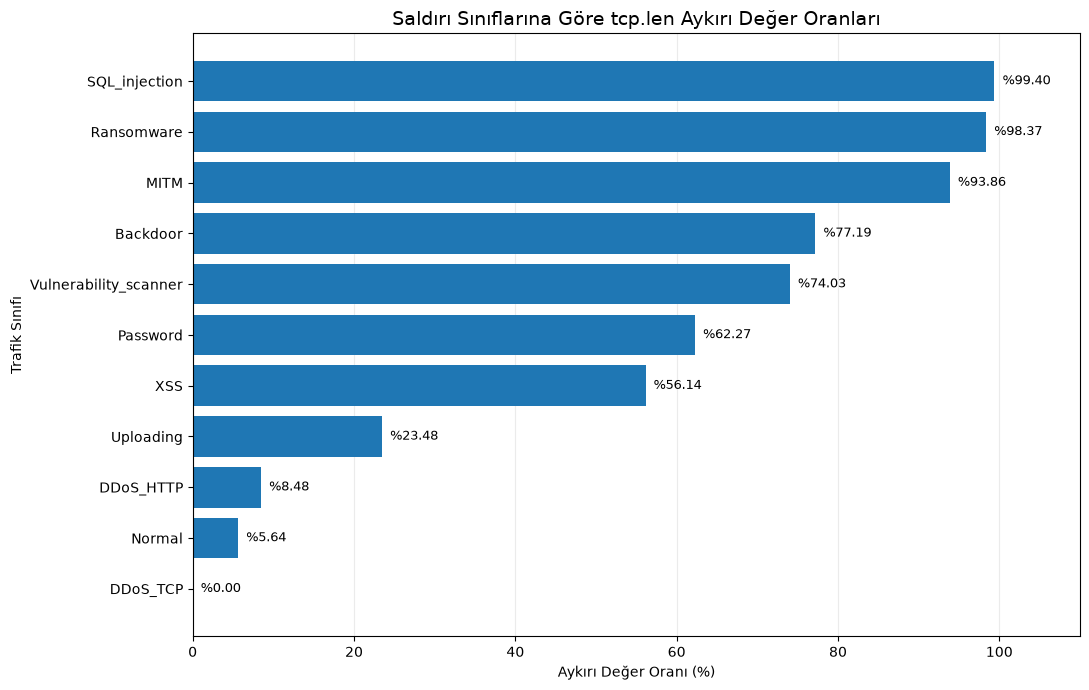

In [25]:

import pandas as pd
import matplotlib.pyplot as plt

# Önceki analizde oluşturulan sonuç tablosunu kullanma
grafik_verisi = aykiri_sinif_tablosu.copy()

# Pozitif ve geçerli veri içermeyen sınıfları hariç tutma
grafik_verisi = grafik_verisi[
    grafik_verisi["Pozitif Geçerli"] > 0
].copy()

# Aykırı değer oranına göre sıralama
grafik_verisi = grafik_verisi.sort_values(
    "Aykırı Oranı (%)",
    ascending=True
)

# Grafik oluşturma
fig, ax = plt.subplots(figsize=(11, 7))

cubuklar = ax.barh(
    grafik_verisi["Saldırı Türü"],
    grafik_verisi["Aykırı Oranı (%)"]
)

# Grafik başlıkları
ax.set_title(
    "Saldırı Sınıflarına Göre tcp.len Aykırı Değer Oranları",
    fontsize=14
)

ax.set_xlabel("Aykırı Değer Oranı (%)")
ax.set_ylabel("Trafik Sınıfı")

# Yüzde eksenini 0-100 aralığında gösterme
ax.set_xlim(0, 110)

# Her çubuğun yanına yüzde değeri yazma
for cubuk in cubuklar:
    oran = cubuk.get_width()

    ax.text(
        oran + 1,
        cubuk.get_y() + cubuk.get_height() / 2,
        f"%{oran:.2f}",
        va="center",
        fontsize=9
    )

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



### 4.20. Aykırı Değerlerin Görselleştirilmesi — Sonuç ve Yorum

Edge-IIoTset çalışma veri setinde `tcp.len` özniteliğine ait IQR aykırı değer oranları, saldırı sınıflarına göre yatay çubuk grafik kullanılarak görselleştirilmiştir.

#### Görselleştirme Sonucunda Elde Edilen Bulgular

Grafikte aykırı değer oranlarının sınıflar arasında önemli farklılıklar gösterdiği belirlenmiştir.

**En yüksek aykırı değer oranına sahip sınıflar:**

- SQL_injection: %99,40
- Ransomware: %98,37
- MITM: %93,86
- Backdoor: %77,19
- Vulnerability_scanner: %74,03

**Daha düşük oranlara sahip sınıflar:**

- DDoS_HTTP: %8,48
- Normal: %5,64
- DDoS_TCP: %0,00

#### Bulguların Değerlendirilmesi

Görselleştirme sonucunda `tcp.len` özniteliğinin dağılımının trafik sınıfları arasında farklılık gösterdiği gözlemlenmiştir.

Özellikle SQL_injection, Ransomware ve MITM sınıflarında, pozitif ve geçerli sayısal değerlerin büyük bölümü genel IQR sınırlarının dışında bulunmaktadır.

Buna karşılık Normal ve DDoS_HTTP sınıflarında aykırı değer oranları daha düşüktür.

DDoS_TCP sınıfında ise incelenen pozitif değerler arasında genel IQR sınırlarının dışında kalan kayıt bulunmamıştır.

Bu oranlar, her sınıfın yalnızca pozitif ve sonlu sayısal `tcp.len` kayıtları üzerinden hesaplanmıştır.

Pozitif ve geçerli sayısal değer bulunmayan sınıflar grafiğe dahil edilmemiştir.

#### Veri Madenciliği Açısından Önemi

Elde edilen bulgular, `tcp.len` özniteliğinin farklı trafik sınıflarında farklı dağılımlara sahip olduğunu göstermektedir.

Bu durum, özniteliğin sınıflandırma açısından ayırt edici bilgi içerebileceğini düşündürmektedir.

Ancak söz konusu farklılıkların saldırı davranışlarından mı yoksa veri toplama ve öznitelik çıkarma süreçlerinden mi kaynaklandığı henüz kesinleştirilmemiştir.

Bu nedenle `tcp.len` özniteliğinin sınıflandırma açısından gerçek katkısı, ilerleyen aşamalarda uygulanacak öznitelik seçimi ve model değerlendirme yöntemleriyle araştırılacaktır.

#### Aykırı Değerlerin Yönetimi

Siber güvenlik veri setlerinde istatistiksel olarak aykırı görünen değerler önemli saldırı örüntülerini temsil edebilir.

Bu nedenle tespit edilen 7.972 aykırı değer adayı otomatik olarak silinmemiş veya sınırlandırılmamıştır.

Aykırı değerlerin korunması veya dönüştürülmesi kararı, veri kalitesi ve model performansı üzerindeki etkileri değerlendirilerek verilecektir.

#### Sonuç

Yatay çubuk grafik aracılığıyla `tcp.len` özniteliğinin aykırı değer oranlarının trafik sınıflarına göre belirgin farklılıklar gösterdiği ortaya konmuştur.

Görselleştirme, sınıflar arasındaki dağılım farklılıklarının anlaşılmasını kolaylaştırmıştır.

Bu aşamada herhangi bir kayıt silinmemiş veya dönüştürülmemiştir.



### 4.21. Veri Temizleme Stratejisinin Belirlenmesi

#### 4.21.1. Sayısal Özniteliklerde Veri Biçimlerinin İncelenmesi

**Amaç:**

Önceki veri kalitesi analizlerinde tespit edilen uyumsuz değerlerin türlerini ve sayılarını belirleyerek veri temizleme işlemleri için uygun bir strateji geliştirmek.

**Yöntem:**

399.992 kayıt içeren temizlenmiş çalışma veri setindeki aşağıdaki öznitelikler incelenecektir:

- tcp.srcport
- tcp.dstport
- tcp.len
- udp.port

Her öznitelikteki değerler aşağıdaki gruplara ayrılacaktır:

1. Boş değerler
2. Sayısal sıfır değerleri
3. Sıfır dışındaki sayısal değerler
4. Hexadecimal biçimli değerler (0x ile başlayanlar)
5. Sayısal olarak yorumlanamayan diğer değerler

Her gruptaki kayıt sayısı hesaplanacak ve şüpheli değerlere ait örnekler görüntülenecektir.

**Beklenen Çıktı:**

İncelenen dört öznitelik için veri biçimi dağılımlarını gösteren bir tablo ve sayısal olmayan değerlere ait örnekler elde edilmesi.

**Önemli Not:**

Bu aşamada hiçbir değer silinmeyecek veya dönüştürülmeyecektir. Elde edilen bulgular sonraki veri temizleme işlemlerinin belirlenmesinde kullanılacaktır.


In [1]:

import pandas as pd
from pathlib import Path

# Güncel çalışma veri setinin yolu
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# İncelenecek öznitelikler
sutunlar = [
    "tcp.srcport",
    "tcp.dstport",
    "tcp.len",
    "udp.port"
]

# Değerleri orijinal metin biçiminde okuma
df = pd.read_csv(
    dosya_yolu,
    usecols=sutunlar,
    dtype=str,
    keep_default_na=False
)

sonuclar = []

print("Toplam kayıt sayısı:", len(df))
print("\nVERİ BİÇİMİ ANALİZİ\n")

for sutun in sutunlar:

    degerler = df[sutun].str.strip()

    # Sayısal dönüşümü yalnızca analiz amacıyla deneme
    sayisal = pd.to_numeric(
        degerler,
        errors="coerce"
    )

    # Değer türlerini belirleme
    bos = degerler.eq("")

    sifir = sayisal.eq(0) & ~bos

    hexadecimal = degerler.str.fullmatch(
        r"0[xX][0-9a-fA-F]+",
        na=False
    )

    sayisal_diger = (
        sayisal.notna()
        & ~sifir
        & ~bos
    )

    diger = ~(
        bos
        | sifir
        | hexadecimal
        | sayisal_diger
    )

    # Sonuçları tabloya ekleme
    sonuclar.append({
        "Öznitelik": sutun,
        "Boş": int(bos.sum()),
        "Sıfır": int(sifir.sum()),
        "Diğer Sayısal": int(sayisal_diger.sum()),
        "Hexadecimal (0x)": int(hexadecimal.sum()),
        "Diğer Biçimler": int(diger.sum())
    })

    # Sayısal olmayan örnekleri görüntüleme
    print(f"\nÖznitelik: {sutun}")

    ornekler = degerler[
        hexadecimal | diger
    ].value_counts().head(5)

    if len(ornekler) > 0:
        print("Şüpheli biçim örnekleri:")
        print(ornekler.to_string())
    else:
        print("Şüpheli biçimde değer bulunamadı.")

# Genel analiz tablosu
sonuc_tablosu = pd.DataFrame(sonuclar)

print("\nGENEL VERİ BİÇİMİ DAĞILIMI:")
display(sonuc_tablosu)

# Kontrol: Her satır yalnızca bir gruba ayrılmalı
kategori_sutunlari = [
    "Boş",
    "Sıfır",
    "Diğer Sayısal",
    "Hexadecimal (0x)",
    "Diğer Biçimler"
]

assert len(df) == 399992

assert (
    sonuc_tablosu[kategori_sutunlari].sum(axis=1)
    == len(df)
).all()

print("\nKontrol başarılı: Tüm değerler sınıflandırıldı.")


Toplam kayıt sayısı: 399992

VERİ BİÇİMİ ANALİZİ


Öznitelik: tcp.srcport
Şüpheli biçim örnekleri:
tcp.srcport
_googlecast._tcp.local    164
DESKTOP-UHF0SF2.local      60
DESKTOP-UHF0SF2            43
_ipps._tcp.local            6

Öznitelik: tcp.dstport
Şüpheli biçim örnekleri:
tcp.dstport
0x00000018    1946
0x00000010     999
0x00000002       5
0x00000012       4
0x00000011       3

Öznitelik: tcp.len
Şüpheli biçim örnekleri:
tcp.len
020405b40103030801010402    5
020405b40101040201030307    4
0101050ac0c5a305c0c5a322    1

Öznitelik: udp.port
Şüpheli biçim örnekleri:
udp.port
_ipp._tcp.local    6

GENEL VERİ BİÇİMİ DAĞILIMI:


,Öznitelik,Boş,Sıfır,Diğer Sayısal,Hexadecimal (0x),Diğer Biçimler
0,tcp.srcport,0,64900,334819,0,273
1,tcp.dstport,0,117672,279362,2957,1
2,tcp.len,0,314259,85723,0,10
3,udp.port,0,399618,368,0,6



Kontrol başarılı: Tüm değerler sınıflandırıldı.



### 4.22. Veri Temizleme İşlemlerinin Uygulanması

**Amaç:**

Edge-IIoTset çalışma veri setindeki seçilmiş sayısal özniteliklerin modelleme için daha tutarlı bir biçime getirilmesi.

**Yöntem:**

tcp.srcport, tcp.dstport, tcp.len ve udp.port özniteliklerinde sayısal dönüşüm uygulanacaktır.

TCP ve UDP port özniteliklerinde 0–65535 aralığındaki tam sayı değerler korunacaktır.

tcp.len özniteliğinde sıfır veya pozitif tam sayı değerler korunacaktır.

Sıfır değerler silinmeyecektir.

Sayısal olarak yorumlanamayan veya belirlenen geçerlilik kurallarını karşılamayan değerler geçici olarak NaN ile işaretlenecektir.

Özellikle anlamsal doğruluğu henüz doğrulanmamış hexadecimal biçimli port değerleri otomatik olarak ondalık sayıya dönüştürülmeyecektir.

Veri kaybını önlemek amacıyla hiçbir satır silinmeyecek ve orijinal CSV dosyası değiştirilmeyecektir.

**Beklenen Çıktı:**

- 399.992 kayıt içeren yeni CSV dosyası
- Dört özniteliğin sayısal biçime dönüştürülmesi
- Uyumsuz değer sayılarının raporlanması
- Orijinal çalışma veri setinin korunması

**Not:**

Oluşturulan eksik değerlerin nasıl doldurulacağına, eğitim ve test verileri ayrıldıktan sonra karar verilecektir. Bu aşamada modelleme için nihai veri hazırlığı tamamlanmış sayılmayacaktır.


In [2]:

import pandas as pd
import numpy as np
from pathlib import Path

# Orijinal temizlenmiş çalışma dosyası
giris_dosyasi = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Temizlenmis.csv"
)

# Yeni çıktı dosyası
cikis_dosyasi = giris_dosyasi.parent / (
    "EdgeIIoT_399992_Tip_Temizligi.csv"
)

# İncelenen öznitelikler
port_sutunlari = [
    "tcp.srcport",
    "tcp.dstport",
    "udp.port"
]

uzunluk_sutunu = "tcp.len"

sutunlar = port_sutunlari + [uzunluk_sutunu]

# Temizleme istatistikleri
uyumsuz_sayilari = {
    sutun: 0 for sutun in sutunlar
}

toplam_kayit = 0
ilk_parca = True

# Verileri parçalar halinde işleme
for parca in pd.read_csv(
    giris_dosyasi,
    chunksize=20000,
    dtype=str,
    na_filter=False
):

    toplam_kayit += len(parca)

    for sutun in sutunlar:

        degerler = parca[sutun].str.strip()

        sayisal = pd.to_numeric(
            degerler,
            errors="coerce"
        )

        # Sayısal ve sonlu değer kontrolü
        gecerli = (
            sayisal.notna()
            & np.isfinite(sayisal)
            & (sayisal >= 0)
            & (sayisal % 1 == 0)
        )

        # Port sütunlarında geçerli aralık kontrolü
        if sutun in port_sutunlari:
            gecerli = gecerli & (sayisal <= 65535)

        # Uyumsuz değer sayısını kaydetme
        uyumsuz_sayilari[sutun] += int(
            (~gecerli).sum()
        )

        # Uyumsuz değerleri NaN olarak işaretleme
        parca[sutun] = sayisal.where(
            gecerli,
            np.nan
        )

    # Yeni CSV dosyasına yazma
    parca.to_csv(
        cikis_dosyasi,
        mode="w" if ilk_parca else "a",
        header=ilk_parca,
        index=False
    )

    ilk_parca = False

print("VERİ TİPİ TEMİZLEME SONUÇLARI")
print("-" * 40)

print("Toplam kayıt sayısı:", toplam_kayit)

for sutun, sayi in uyumsuz_sayilari.items():
    print(f"{sutun}: {sayi} uyumsuz değer")

print(
    "Toplam işaretlenen hücre:",
    sum(uyumsuz_sayilari.values())
)

print("\nYeni CSV dosyası:")
print(cikis_dosyasi)

assert toplam_kayit == 399992

print("\nİşlem tamamlandı.")


VERİ TİPİ TEMİZLEME SONUÇLARI
----------------------------------------
Toplam kayıt sayısı: 399992
tcp.srcport: 273 uyumsuz değer
tcp.dstport: 2958 uyumsuz değer
udp.port: 6 uyumsuz değer
tcp.len: 10 uyumsuz değer
Toplam işaretlenen hücre: 3247

Yeni CSV dosyası:
E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Tip_Temizligi.csv

İşlem tamamlandı.



### 4.22. Veri Temizleme İşlemlerinin Uygulanması — Sonuç ve Yorum

399.992 kayıt içeren Edge-IIoTset çalışma veri setinde seçilmiş dört öznitelik üzerinde sayısal veri tipi temizleme işlemi uygulanmıştır.

#### Temizleme Sonuçları

| Öznitelik | Uyumsuz Değer Sayısı |
|---|---:|
| tcp.srcport | 273 |
| tcp.dstport | 2.958 |
| tcp.len | 10 |
| udp.port | 6 |
| **Toplam** | **3.247** |

Belirlenen kurallara uymayan toplam 3.247 hücre, yeni çalışma dosyasında eksik değer (NaN) olarak işaretlenmiştir.

Bu işlemde:

- Sayısal sıfır değerler korunmuştur.
- TCP ve UDP portları için 0–65535 aralığındaki tam sayılar kabul edilmiştir.
- tcp.len için sıfır veya pozitif tam sayılar kabul edilmiştir.
- Uygun olmayan değerler sayısal dönüşüm sonucunda NaN olarak işaretlenmiştir.
- Hiçbir kayıt silinmemiştir.
- Orijinal çalışma dosyası korunarak ayrı bir CSV dosyası oluşturulmuştur.

#### Bulguların Değerlendirilmesi

Önceki analizlerde belirlenen sayısal biçim uyumsuzluklarının yeni veri setinde geçici eksik değerler olarak temsil edilmesi sağlanmıştır.

Böylece ilgili özniteliklerin modelleme öncesi sayısal dönüşüm aşamasına hazırlanması amaçlanmıştır.

Ancak bu işlem, özniteliklerin anlamsal doğruluğunun tamamen sağlandığı anlamına gelmemektedir.

Özellikle hexadecimal biçimli ve servis adlarına benzeyen orijinal değerler, bilgi kaybının izlenebilmesi amacıyla kaynak dosyada korunmuştur.

#### Sonuç

Toplam 3.247 uyumsuz hücre işaretlenmiş ve EdgeIIoT_399992_Tip_Temizligi.csv adlı yeni çalışma dosyası oluşturulmuştur.

Bu aşamada eksik değer doldurma işlemi uygulanmamıştır.

Sonraki aşamada dosyanın bütünlüğü, kayıt ve sütun sayıları, sınıf etiketleri ve sayısal dönüşüm sonuçları doğrulanacaktır.



### 4.23. Temizlenmiş Veri Setinin Doğrulanması

**Amaç:**

Sayısal veri tipi temizleme işleminden sonra oluşturulan CSV dosyasının bütünlüğünü ve dönüşüm sonuçlarının doğruluğunu kontrol etmek.

**Yöntem:**

Temizleme öncesi ve sonrası CSV dosyaları karşılaştırılacaktır.

Aşağıdaki kontroller gerçekleştirilecektir:

1. Toplam kayıt ve sütun sayılarının karşılaştırılması.
2. Saldırı sınıflarının ve hedef etiketlerin korunması.
3. Dönüştürülmeyen sütunların değişmediğinin doğrulanması.
4. Dört öznitelikte oluşturulan eksik değerlerin sayılması.
5. Geçerli sayısal değerlerin ve sıfırların korunduğunun kontrol edilmesi.

**Beklenen Çıktı:**

Temizlenmiş dosyanın önceki veri setiyle tutarlı olduğunu gösteren kontrol sonuçları.

Bu aşamada veri üzerinde yeni bir değişiklik yapılmayacaktır.


In [3]:

import pandas as pd
import numpy as np
from pathlib import Path

# Dosya yolları
klasor = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri"
)

eski_dosya = klasor / "EdgeIIoT_399992_Temizlenmis.csv"
yeni_dosya = klasor / "EdgeIIoT_399992_Tip_Temizligi.csv"

port_sutunlari = ["tcp.srcport", "tcp.dstport", "udp.port"]
kontrol_sutunlari = port_sutunlari + ["tcp.len"]

# Kontrol sayaçları
eksik_sayilari = {s: 0 for s in kontrol_sutunlari}
sifir_sayilari = {s: 0 for s in kontrol_sutunlari}

toplam_eski = 0
toplam_yeni = 0
siniflar = set()

eski_okuyucu = pd.read_csv(
    eski_dosya, dtype=str, na_filter=False, chunksize=20000
)

yeni_okuyucu = pd.read_csv(
    yeni_dosya, dtype=str, na_filter=False, chunksize=20000
)

# İki dosyayı aynı sırayla karşılaştırma
for eski in eski_okuyucu:

    yeni = next(yeni_okuyucu, None)

    assert yeni is not None, "Yeni dosyada kayıt eksik!"

    assert list(eski.columns) == list(yeni.columns), (
        "Sütunlar farklı!"
    )

    assert len(eski.columns) == 63
    assert len(eski) == len(yeni), "Kayıt sayıları farklı!"

    toplam_eski += len(eski)
    toplam_yeni += len(yeni)

    siniflar.update(yeni["Attack_type"].unique())

    # Değiştirilmemesi gereken 59 sütunu kontrol etme
    diger_sutunlar = [
        s for s in eski.columns
        if s not in kontrol_sutunlari
    ]

    assert eski[diger_sutunlar].equals(
        yeni[diger_sutunlar]
    ), "Diğer sütunlarda beklenmeyen değişiklik!"

    # Dönüştürülen dört sütunun doğruluğunu kontrol etme
    for sutun in kontrol_sutunlari:

        eski_sayisal = pd.to_numeric(
            eski[sutun].str.strip(),
            errors="coerce"
        )

        yeni_metin = yeni[sutun].str.strip()

        yeni_sayisal = pd.to_numeric(
            yeni_metin,
            errors="coerce"
        )

        gecerli = (
            eski_sayisal.notna()
            & np.isfinite(eski_sayisal)
            & (eski_sayisal >= 0)
            & (eski_sayisal % 1 == 0)
        )

        if sutun in port_sutunlari:
            gecerli = gecerli & (eski_sayisal <= 65535)

        # Geçersiz eski değerler yeni dosyada boş olmalı
        assert yeni_metin[~gecerli].eq("").all(), (
            f"{sutun}: Uyumsuz değerler temizlenmemiş!"
        )

        # Geçerli değerler korunmuş olmalı
        assert yeni_sayisal[gecerli].notna().all()

        assert np.allclose(
            eski_sayisal[gecerli],
            yeni_sayisal[gecerli],
            rtol=0,
            atol=1e-8
        ), f"{sutun}: Geçerli değerler değişmiş!"

        eksik_sayilari[sutun] += int(
            yeni_metin.eq("").sum()
        )

        sifir_sayilari[sutun] += int(
            yeni_sayisal.eq(0).sum()
        )

# Yeni dosyada fazladan kayıt bulunmamalı
assert next(yeni_okuyucu, None) is None

# Nihai kontroller
assert toplam_eski == toplam_yeni == 399992
assert len(siniflar) == 15
assert sum(eksik_sayilari.values()) == 3247

print("VERİ TEMİZLEME DOĞRULAMA SONUÇLARI")
print("-" * 45)

print("Önceki kayıt sayısı:", toplam_eski)
print("Yeni kayıt sayısı:", toplam_yeni)
print("Sütun sayısı:", 63)
print("Sınıf sayısı:", len(siniflar))

print("\nDÖNÜŞÜM SONRASI ÖZET:")

sonuc = pd.DataFrame({
    "Öznitelik": kontrol_sutunlari,
    "Oluşan Eksik Değer": [
        eksik_sayilari[s] for s in kontrol_sutunlari
    ],
    "Korunan Sıfır": [
        sifir_sayilari[s] for s in kontrol_sutunlari
    ]
})

display(sonuc)

print("Toplam eksik işaretlenen hücre:",
      sum(eksik_sayilari.values()))

print("\nKontroller başarılı!")
print("Orijinal kayıtlar ve hedef etiketler korundu.")


VERİ TEMİZLEME DOĞRULAMA SONUÇLARI
---------------------------------------------
Önceki kayıt sayısı: 399992
Yeni kayıt sayısı: 399992
Sütun sayısı: 63
Sınıf sayısı: 15

DÖNÜŞÜM SONRASI ÖZET:


,Öznitelik,Oluşan Eksik Değer,Korunan Sıfır
0,tcp.srcport,273,64900
1,tcp.dstport,2958,117672
2,udp.port,6,399618
3,tcp.len,10,314259


Toplam eksik işaretlenen hücre: 3247

Kontroller başarılı!
Orijinal kayıtlar ve hedef etiketler korundu.



### 4.23. Temizlenmiş Veri Setinin Doğrulanması — Sonuç ve Yorum

Sayısal veri tipi temizleme işleminden sonra oluşturulan yeni çalışma veri setinin bütünlüğü ve dönüşüm sonuçları kontrol edilmiştir.

#### Doğrulama Sonuçları

- Temizleme öncesi kayıt sayısı: 399.992
- Temizleme sonrası kayıt sayısı: 399.992
- Sütun sayısı: 63
- Trafik sınıfı sayısı: 15
- Eksik değer olarak işaretlenen hücre sayısı: 3.247

| Öznitelik | Oluşan Eksik Değer | Korunan Sıfır |
|---|---:|---:|
| tcp.srcport | 273 | 64.900 |
| tcp.dstport | 2.958 | 117.672 |
| udp.port | 6 | 399.618 |
| tcp.len | 10 | 314.259 |

#### Bulguların Değerlendirilmesi

Temizleme öncesi ve sonrası veri setleri karşılaştırıldığında toplam kayıt sayısının, sütun yapısının ve hedef değişkenlerin korunduğu doğrulanmıştır.

Dönüştürme işlemi uygulanmayan 59 sütunda beklenmeyen bir değişiklik tespit edilmemiştir.

İncelenen dört öznitelikte geçerli sayısal değerlerin ve sıfırların korunduğu, belirlenen kurallara uygun olmayan değerlerin ise eksik olarak işaretlendiği doğrulanmıştır.

Bu işlem sonucunda 3.247 hücrede eksik değer oluşturulmuştur. Ancak hiçbir satır veri setinden çıkarılmamıştır.

#### Sonuç

Seçilmiş dört sayısal öznitelik üzerinde gerçekleştirilen veri tipi temizleme işleminin teknik doğrulama kontrolleri başarıyla tamamlanmıştır.

Yeni veri seti EdgeIIoT_399992_Tip_Temizligi.csv adıyla kaydedilmiştir.

Bununla birlikte mevcut kontroller, veri setindeki bütün özniteliklerin anlamsal açıdan doğru olduğunu kanıtlamamaktadır.

Diğer özniteliklerin veri türleri de incelenerek veri temizleme sürecinin kapsamlı değerlendirmesi tamamlanacaktır.



### 4.24. Diğer Özniteliklerin Veri Tipi Kontrolü

**Amaç:**

Veri setindeki 61 giriş özniteliğinin veri biçimlerini inceleyerek önceki temizleme işlemlerinin dışında kalan olası veri tipi uyumsuzluklarını belirlemek.

**Yöntem:**

Tüm giriş öznitelikleri aşağıdaki biçimlere göre değerlendirilecektir:

- Sayısal değerler
- Sayısal olmayan metinsel değerler
- Boş değerler
- Sayısal ve metinsel değerlerin birlikte bulunduğu sütunlar

Her öznitelik için toplam değer sayıları hesaplanacaktır. Karışık biçimli sütunlarda sayısal olmayan değerlerden örnekler görüntülenecektir.

**Beklenen Çıktı:**

Özniteliklerin biçim dağılımlarını ve ilave inceleme gerektiren sütunları gösteren özet tablolar.

**Önemli Not:**

Metinsel değer içeren her sütun hatalı değildir. IP adresleri, zaman bilgileri ve kategorik değişkenler doğal olarak metinsel biçimde bulunabilir.

Bu aşamada veri üzerinde herhangi bir değişiklik yapılmayacaktır.


In [5]:

import pandas as pd
import numpy as np
from pathlib import Path

# Güncel temizlenmiş veri seti
dosya_yolu = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Tip_Temizligi.csv"
)

# Sütun adlarını okuma
tum_sutunlar = pd.read_csv(
    dosya_yolu,
    nrows=0
).columns.tolist()

# Hedef değişkenleri analiz dışında bırakma
hedefler = ["Attack_label", "Attack_type"]

oznitelikler = [
    sutun for sutun in tum_sutunlar
    if sutun not in hedefler
]

print("Toplam sütun sayısı:", len(tum_sutunlar))
print("Giriş özniteliği sayısı:", len(oznitelikler))

# Her öznitelik için sayaçlar
istatistikler = {
    sutun: {
        "Sayısal": 0,
        "Metinsel": 0,
        "Boş": 0
    }
    for sutun in oznitelikler
}

# Metinsel değer örnekleri
metin_ornekleri = {
    sutun: [] for sutun in oznitelikler
}

toplam_kayit = 0

# Bellek kullanımını azaltmak için parçalı okuma
for parca in pd.read_csv(
    dosya_yolu,
    chunksize=20000,
    dtype=str,
    na_filter=False
):

    toplam_kayit += len(parca)

    for sutun in oznitelikler:

        degerler = parca[sutun].str.strip()

        # Boş değerleri belirleme
        bos_maskesi = degerler.eq("")

        # Sayısal dönüşüm kontrolü
        sayisal = pd.to_numeric(
            degerler,
            errors="coerce"
        )

        sayisal_maskesi = (
            sayisal.notna()
            & np.isfinite(sayisal)
        )

        # Metinsel veya diğer uyumsuz biçimler
        metin_maskesi = (
            ~bos_maskesi
            & ~sayisal_maskesi
        )

        # Sayaçları güncelleme
        istatistikler[sutun]["Sayısal"] += int(
            sayisal_maskesi.sum()
        )

        istatistikler[sutun]["Metinsel"] += int(
            metin_maskesi.sum()
        )

        istatistikler[sutun]["Boş"] += int(
            bos_maskesi.sum()
        )

        # En fazla üç farklı metinsel örnek toplama
        if len(metin_ornekleri[sutun]) < 3:

            for deger in degerler[
                metin_maskesi
            ].drop_duplicates():

                if deger not in metin_ornekleri[sutun]:
                    metin_ornekleri[sutun].append(deger)

                if len(metin_ornekleri[sutun]) >= 3:
                    break

# Sonuç tablosunu oluşturma
sonuclar = []

for sutun in oznitelikler:

    bilgi = istatistikler[sutun]

    if bilgi["Sayısal"] > 0 and bilgi["Metinsel"] > 0:
        veri_tipi = "Karışık"

    elif bilgi["Metinsel"] > 0:
        veri_tipi = "Metinsel"

    elif bilgi["Sayısal"] > 0:
        veri_tipi = "Sayısal"

    else:
        veri_tipi = "Tamamen Boş"

    ornekler = [
        str(deger)[:60]
        for deger in metin_ornekleri[sutun]
    ]

    sonuclar.append({
        "Öznitelik": sutun,
        "Sayısal": bilgi["Sayısal"],
        "Metinsel": bilgi["Metinsel"],
        "Boş": bilgi["Boş"],
        "Biçim": veri_tipi,
        "Metinsel Örnekler": " | ".join(ornekler)
    })

sonuc_tablosu = pd.DataFrame(sonuclar)

print("\nTOPLAM İNCELENEN KAYIT:", toplam_kayit)

print("\nÖZNİTELİK BİÇİMLERİNİN ÖZETİ:")
display(
    sonuc_tablosu["Biçim"].value_counts().to_frame("Sayı")
)

print("\nKARIŞIK BİÇİMLİ ÖZNİTELİKLER:")
display(
    sonuc_tablosu[
        sonuc_tablosu["Biçim"] == "Karışık"
    ]
)

print("\nMETİNSEL ÖZNİTELİKLER:")
display(
    sonuc_tablosu[
        sonuc_tablosu["Biçim"] == "Metinsel"
    ]
)

print("\nTÜM ÖZNİTELİKLERİN ANALİZİ:")
display(sonuc_tablosu)

# Bütünlük kontrolleri
assert len(oznitelikler) == 61
assert toplam_kayit == 399992

assert all(
    bilgi["Sayısal"]
    + bilgi["Metinsel"]
    + bilgi["Boş"] == toplam_kayit
    for bilgi in istatistikler.values()
)

print("\nKontrol başarılı! 61 öznitelik incelendi.")


Toplam sütun sayısı: 63
Giriş özniteliği sayısı: 61

TOPLAM İNCELENEN KAYIT: 399992

ÖZNİTELİK BİÇİMLERİNİN ÖZETİ:


,Sayı
Biçim,
Sayısal,33
Karışık,28



KARIŞIK BİÇİMLİ ÖZNİTELİKLER:


,Öznitelik,Sayısal,Metinsel,Boş,Biçim,Metinsel Örnekler
0,frame.time,310,399682,0,Karışık,2021 17:58:52.923982000 | 2021 17:59:00.073310...
1,ip.src_host,5908,394084,0,Karışık,192.168.0.170 | 192.168.0.128 | 0.0.0.0
2,ip.dst_host,64321,335671,0,Karışık,192.168.0.128 | 192.168.0.170 | 224.0.0.1
3,arp.dst.proto_ipv4,394138,5854,0,Karışık,192.168.0.170 | 192.168.0.128 | 192.168.0.1
5,arp.hw.size,399983,9,0,Karışık,192.168.0.128 | 192.168.0.1 | 192.168.7.55
6,arp.src.proto_ipv4,399805,187,0,Karışık,192.168.0.128 | 192.168.0.170 | 192.168.0.101
7,icmp.checksum,344247,55745,0,Karışık,0x000042f2 | 0x000025f2 | 0x000013f2
8,icmp.seq_le,394325,5667,0,Karışık,0x00006b26 | 0x0000164e | 0x00002a55
11,http.file_data,396436,3556,0,Karışık,"<!DOCTYPE HTML PUBLIC ""-//IETF//DTD HTML 2.0//..."
13,http.request.uri.query,399399,593,0,Karışık,id=2&Submit=Submitid%3D53%20AND%208819%3D2628-...



METİNSEL ÖZNİTELİKLER:


,Öznitelik,Sayısal,Metinsel,Boş,Biçim,Metinsel Örnekler



TÜM ÖZNİTELİKLERİN ANALİZİ:


,Öznitelik,Sayısal,Metinsel,Boş,Biçim,Metinsel Örnekler
0,frame.time,310,399682,0,Karışık,2021 17:58:52.923982000 | 2021 17:59:00.073310...
1,ip.src_host,5908,394084,0,Karışık,192.168.0.170 | 192.168.0.128 | 0.0.0.0
2,ip.dst_host,64321,335671,0,Karışık,192.168.0.128 | 192.168.0.170 | 224.0.0.1
3,arp.dst.proto_ipv4,394138,5854,0,Karışık,192.168.0.170 | 192.168.0.128 | 192.168.0.1
4,arp.opcode,399992,0,0,Sayısal,
...,...,...,...,...,...,...
56,mqtt.topic_len,399992,0,0,Sayısal,
57,mqtt.ver,399992,0,0,Sayısal,
58,mbtcp.len,399992,0,0,Sayısal,
59,mbtcp.trans_id,399992,0,0,Sayısal,



Kontrol başarılı! 61 öznitelik incelendi.



### 4.24. Diğer Özniteliklerin Veri Tipi Kontrolü — Sonuç ve Yorum

399.992 kayıt içeren Edge-IIoTset çalışma veri setindeki 61 giriş özniteliğinin veri biçimleri incelenmiştir.

#### Analiz Sonuçları

| Veri Biçimi | Öznitelik Sayısı |
|---|---:|
| Sayısal | 33 |
| Karışık | 28 |
| Tamamen metinsel | 0 |
| Toplam | 61 |

Analiz sonucunda 33 öznitelikte sayısal ve varsa boş değerlerin bulunduğu, 28 öznitelikte ise hem sayısal hem de metinsel değerlerin yer aldığı belirlenmiştir.

#### Bulguların Değerlendirilmesi

Karışık biçimli özniteliklerin tamamı hatalı veri olarak değerlendirilmemiştir.

Örneğin:

- ip.src_host ve ip.dst_host sütunları IP adreslerini içerebilmektedir.
- http.request.method sütununda GET ve POST gibi HTTP yöntemleri bulunmaktadır.
- mqtt.topic sütununda MQTT konu adları yer almaktadır.
- tcp.flags gibi bazı alanlarda hexadecimal gösterimler bulunmaktadır.

Bu değerler ilgili protokollerin özellikleri nedeniyle anlamlı olabilir.

Bununla birlikte bazı sütunlarda anlamsal açıdan şüpheli değerler tespit edilmiştir.

Örneğin arp.hw.size sütununda IP adresleri, dns.qry.name.len sütununda alan adları ve tcp.connection.fin sütununda hexadecimal biçimli bir değer gözlemlenmiştir.

Bu durum, bazı özniteliklerde veri türü uyumsuzluğunun ötesinde anlamsal tutarlılık sorunları olabileceğini göstermektedir.

#### Veri Temizleme Açısından Önemi

Metinsel değerlerin tamamının eksik değer olarak işaretlenmesi uygun değildir. Kategorik ve protokole özgü bilgiler modelleme açısından yararlı olabilir.

Bu nedenle sayısal, kategorik ve anlamsal açıdan şüpheli öznitelikler farklı ön işleme stratejileriyle ele alınmalıdır.

Ayrıca sayısal biçimde bulunan her değerin ilgili özniteliği anlamsal olarak doğru temsil ettiği varsayılamaz.

#### Sonuç

61 giriş özniteliğinin veri biçimi analizi tamamlanmış ve 28 karışık biçimli öznitelik belirlenmiştir.

Bazı metinsel değerlerin protokol açısından anlamlı olduğu, bazı değerlerin ise ek doğrulama gerektirdiği sonucuna ulaşılmıştır.

Bu aşamada veri üzerinde değişiklik yapılmamıştır.

Sonraki aşamada anlamsal açıdan şüpheli özniteliklerin içerikleri ve saldırı sınıflarına göre dağılımları incelenecektir.



### 4.25. Son Veri Temizleme İşlemleri

**Amaç:**

Önceki veri kalitesi analizlerinde belirlenen ve özniteliklerin beklenen anlamlarıyla uyumlu olmayan değerleri düzenlemek.

**Yöntem:**

399.992 kayıtlık çalışma veri setinde üç öznitelik incelenecektir:

- arp.hw.size
- dns.qry.name.len
- tcp.connection.fin

arp.hw.size ve dns.qry.name.len sütunlarında 0–255 aralığındaki tam sayı değerleri korunacaktır.

tcp.connection.fin sütununda yalnızca 0 ve 1 değerleri kabul edilecektir.

Bu kurallara uymayan değerler, orijinal bilgiyi tahmin ederek değiştirmek yerine eksik değer (NaN) olarak işaretlenecektir.

Diğer öznitelikler korunacak ve satır silinmeyecektir.

Önceki temizleme dosyası değiştirilmeden yeni bir CSV oluşturulacaktır.

**Beklenen Çıktı:**

- Üç öznitelikteki uyumsuz değer sayıları
- 399.992 kayıtlık yeni çalışma veri seti
- Sonraki modelleme aşamalarında kullanılabilecek güncellenmiş CSV dosyası

**Önemli Not:**

Bu işlem belirlenen biçim ve aralık kurallarına dayanmaktadır. Kuralları karşılayan her sayısal değerin anlamsal doğruluğunu garanti etmez.

Kategorik değişkenlerin kodlanması ve eksik değerlerin doldurulması, eğitim ve test verileri ayrıldıktan sonra uygulanacaktır.


In [6]:

import pandas as pd
import numpy as np
from pathlib import Path

# Çalışma klasörü
klasor = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri"
)

# Önceki temizlenmiş veri seti
giris_dosyasi = klasor / "EdgeIIoT_399992_Tip_Temizligi.csv"

# Yeni çıktı dosyası
cikis_dosyasi = klasor / "EdgeIIoT_399992_Son_Temizlik.csv"

# Özniteliklere uygulanacak geçerlilik sınırları
kurallar = {
    "arp.hw.size": (0, 255),
    "dns.qry.name.len": (0, 255),
    "tcp.connection.fin": (0, 1)
}

# Temizleme sayaçları
yeni_uyumsuz_sayilari = {
    sutun: 0 for sutun in kurallar
}

toplam_kayit = 0
ilk_parca = True

# Dosyayı parçalar halinde işleme
for parca in pd.read_csv(
    giris_dosyasi,
    chunksize=20000,
    dtype=str,
    na_filter=False
):

    toplam_kayit += len(parca)

    for sutun, (alt_sinir, ust_sinir) in kurallar.items():

        # Orijinal değerleri koruyarak kontrol etme
        degerler = parca[sutun].str.strip()

        sayisal = pd.to_numeric(
            degerler,
            errors="coerce"
        )

        # Sayısal, sonlu, tam sayı ve aralık kontrolü
        gecerli = (
            sayisal.notna()
            & np.isfinite(sayisal)
            & sayisal.between(alt_sinir, ust_sinir)
            & (sayisal % 1 == 0)
        )

        # Geçersiz değerlerin sayısını toplama
        yeni_uyumsuz_sayilari[sutun] += int(
            (~gecerli).sum()
        )

        # Uygun olmayan değerleri NaN olarak işaretleme
        parca[sutun] = sayisal.where(
            gecerli,
            np.nan
        )

    # Yeni CSV dosyasına yazma
    parca.to_csv(
        cikis_dosyasi,
        mode="w" if ilk_parca else "a",
        header=ilk_parca,
        index=False
    )

    ilk_parca = False

# İşlem sonuçları
print("4.25 - SON VERİ TEMİZLEME SONUÇLARI")
print("-" * 45)

print("Toplam kayıt sayısı:", toplam_kayit)

for sutun, sayi in yeni_uyumsuz_sayilari.items():
    print(f"{sutun}: {sayi} uyumsuz değer")

print(
    "\nBu aşamada işaretlenen toplam hücre:",
    sum(yeni_uyumsuz_sayilari.values())
)

print("\nYeni CSV dosyası:")
print(cikis_dosyasi)

assert toplam_kayit == 399992

print("\nİşlem tamamlandı.")


4.25 - SON VERİ TEMİZLEME SONUÇLARI
---------------------------------------------
Toplam kayıt sayısı: 399992
arp.hw.size: 9 uyumsuz değer
dns.qry.name.len: 26 uyumsuz değer
tcp.connection.fin: 1 uyumsuz değer

Bu aşamada işaretlenen toplam hücre: 36

Yeni CSV dosyası:
E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri\EdgeIIoT_399992_Son_Temizlik.csv

İşlem tamamlandı.



### 4.26. Nihai Veri Kontrolü

**Amaç:**

Son veri temizleme işlemlerinden sonra oluşturulan CSV dosyasının bütünlüğünü, hedef etiketlerin korunmasını ve uygulanan dönüşümlerin doğruluğunu kontrol etmek.

**Yöntem:**

Son temizleme öncesi ve sonrası veri setleri karşılaştırılacaktır.

Kontrol kapsamında:

1. Kayıt ve sütun sayıları doğrulanacaktır.
2. Saldırı sınıfları ve hedef etiketler karşılaştırılacaktır.
3. Değiştirilmemesi gereken sütunların korunduğu kontrol edilecektir.
4. Son üç öznitelikteki geçersiz değerlerin eksik olarak işaretlendiği doğrulanacaktır.
5. Önceki ve son temizleme aşamalarında oluşturulan eksik değer sayıları hesaplanacaktır.

**Beklenen Çıktı:**

399.992 kayıt, 63 sütun ve 15 trafik sınıfının korunduğunu; toplam 3.283 hücrenin belirlenen kurallara göre eksik değer olarak işaretlendiğini doğrulayan sonuç tablosu.

**Not:**

Bu kontrol veri temizleme işlemlerinin teknik tutarlılığını doğrular. Tüm özniteliklerin anlamsal doğruluğunu veya modelleme için nihai uygunluğunu garanti etmez.


In [7]:

import pandas as pd
import numpy as np
from pathlib import Path
from itertools import zip_longest

# Çalışma klasörü
klasor = Path(
    r"E:\Data mining\Network_Intrusion_Detection\Calisma_Verileri"
)

onceki_dosya = klasor / "EdgeIIoT_399992_Tip_Temizligi.csv"
son_dosya = klasor / "EdgeIIoT_399992_Son_Temizlik.csv"

# Son aşamada temizlenen öznitelikler
kurallar = {
    "arp.hw.size": (0, 255),
    "dns.qry.name.len": (0, 255),
    "tcp.connection.fin": (0, 1)
}

# Önceki aşamada temizlenen öznitelikler
onceki_sutunlar = [
    "tcp.srcport",
    "tcp.dstport",
    "tcp.len",
    "udp.port"
]

yeni_eksik = {sutun: 0 for sutun in kurallar}
onceki_eksik = {sutun: 0 for sutun in onceki_sutunlar}

toplam_kayit = 0
siniflar = set()

# İki dosyayı parçalar halinde okuma
eski_okuyucu = pd.read_csv(
    onceki_dosya,
    dtype=str,
    na_filter=False,
    chunksize=20000
)

yeni_okuyucu = pd.read_csv(
    son_dosya,
    dtype=str,
    na_filter=False,
    chunksize=20000
)

for eski, yeni in zip_longest(eski_okuyucu, yeni_okuyucu):

    assert eski is not None and yeni is not None, (
        "Dosyaların kayıt sayıları farklı!"
    )

    assert list(eski.columns) == list(yeni.columns)
    assert len(yeni.columns) == 63
    assert len(eski) == len(yeni)

    toplam_kayit += len(yeni)
    siniflar.update(yeni["Attack_type"].unique())

    # Temizleme yapılmayan sütunların kontrolü
    degismeyen_sutunlar = [
        s for s in eski.columns
        if s not in kurallar
    ]

    assert eski[degismeyen_sutunlar].equals(
        yeni[degismeyen_sutunlar]
    ), "Beklenmeyen sütun değişikliği!"

    # Son üç sütunun dönüşüm kontrolü
    for sutun, (alt, ust) in kurallar.items():

        eski_sayisal = pd.to_numeric(
            eski[sutun].str.strip(),
            errors="coerce"
        )

        yeni_metin = yeni[sutun].str.strip()

        yeni_sayisal = pd.to_numeric(
            yeni_metin,
            errors="coerce"
        )

        gecerli = (
            eski_sayisal.notna()
            & np.isfinite(eski_sayisal)
            & eski_sayisal.between(alt, ust)
            & (eski_sayisal % 1 == 0)
        )

        # Geçersiz değerlerin boş yazıldığını doğrulama
        assert yeni_metin[~gecerli].eq("").all()

        # Geçerli değerlerin korunduğunu doğrulama
        assert np.allclose(
            eski_sayisal[gecerli],
            yeni_sayisal[gecerli],
            rtol=0,
            atol=0
        )

        yeni_eksik[sutun] += int(
            yeni_metin.eq("").sum()
        )

    # Önceki aşamada oluşturulan eksik değerler
    for sutun in onceki_sutunlar:
        onceki_eksik[sutun] += int(
            yeni[sutun].str.strip().eq("").sum()
        )

# Genel doğrulama
assert toplam_kayit == 399992
assert len(siniflar) == 15
assert sum(onceki_eksik.values()) == 3247
assert sum(yeni_eksik.values()) == 36

toplam_eksik = (
    sum(onceki_eksik.values())
    + sum(yeni_eksik.values())
)

assert toplam_eksik == 3283

# Sonuç tablosu
sonuclar = []

for sutun, sayi in {**onceki_eksik, **yeni_eksik}.items():
    sonuclar.append({
        "Öznitelik": sutun,
        "Eksik Olarak İşaretlenen": sayi
    })

print("4.26 - NİHAİ VERİ KONTROLÜ")
print("-" * 45)

print("Toplam kayıt:", toplam_kayit)
print("Toplam sütun:", 63)
print("Trafik sınıfı:", len(siniflar))

print("\nTEMİZLEME SONUÇLARI:")
display(pd.DataFrame(sonuclar))

print("Toplam işaretlenen hücre:", toplam_eksik)
print("\nTÜM TEKNİK KONTROLLER BAŞARILI!")
print("Veri temizleme aşamasının doğrulaması tamamlandı.")


4.26 - NİHAİ VERİ KONTROLÜ
---------------------------------------------
Toplam kayıt: 399992
Toplam sütun: 63
Trafik sınıfı: 15

TEMİZLEME SONUÇLARI:


,Öznitelik,Eksik Olarak İşaretlenen
0,tcp.srcport,273
1,tcp.dstport,2958
2,tcp.len,10
3,udp.port,6
4,arp.hw.size,9
5,dns.qry.name.len,26
6,tcp.connection.fin,1


Toplam işaretlenen hücre: 3283

TÜM TEKNİK KONTROLLER BAŞARILI!
Veri temizleme aşamasının doğrulaması tamamlandı.



### 4.26. Nihai Veri Kontrolü — Sonuç ve Yorum

Edge-IIoTset çalışma veri setine uygulanan veri temizleme işlemlerinin ardından son doğrulama kontrolleri gerçekleştirilmiştir.

#### Doğrulama Sonuçları

- Toplam kayıt sayısı: 399.992
- Toplam sütun sayısı: 63
- Trafik sınıfı sayısı: 15
- Eksik değer olarak işaretlenen toplam hücre: 3.283

| Öznitelik | İşaretlenen Hücre |
|---|---:|
| tcp.srcport | 273 |
| tcp.dstport | 2.958 |
| tcp.len | 10 |
| udp.port | 6 |
| arp.hw.size | 9 |
| dns.qry.name.len | 26 |
| tcp.connection.fin | 1 |
| **Toplam** | **3.283** |

#### Bulguların Değerlendirilmesi

Veri temizleme işlemleri öncesi ve sonrası dosyalar karşılaştırılarak kayıt ve sütun sayılarının korunduğu doğrulanmıştır.

Saldırı sınıflarında ve hedef değişkenlerde beklenmeyen bir değişiklik tespit edilmemiştir.

Belirlenen biçim ve değer aralığı kurallarını karşılamayan toplam 3.283 hücre eksik değer olarak işaretlenmiştir.

Hiçbir kayıt silinmemiş ve orijinal çalışma dosyaları korunmuştur.

Yapılan işlemler, seçilmiş özniteliklerdeki biçim uyumsuzluklarının yönetilmesini sağlamıştır. Bununla birlikte bütün özniteliklerin anlamsal doğruluğu garanti edilmemektedir.

#### Sonuç

Belirlenen veri temizleme işlemleri ve teknik doğrulama kontrolleri başarıyla tamamlanmıştır.

Çalışma veri seti `EdgeIIoT_399992_Son_Temizlik.csv` dosyasına kaydedilmiştir.

Oluşturulan eksik değerlerin doldurulması, kategorik değişkenlerin kodlanması ve modele özgü dönüşümler sonraki veri hazırlama aşamalarına bırakılmıştır.

Bu işlemler eğitim verileri üzerinde öğrenilerek test verilerine uygulanacak, böylece veri sızıntısı riski azaltılacaktır.

Veri temizleme bölümünün bu aşamadaki çalışmaları tamamlanmıştır.
